# Predicting Hotel Booking Cancellations
**Student ID:** 2025NS04132 · **Group:** 44 · **Course:** Machine Learning, Assignment 2 (M.Tech DSE)

**Dataset:** 119,390 hotel booking records (Kaggle *Hotel Booking Demand*) · 32 features

**Problem Statement** Hotel booking cancellations are a significant operational challenge in the hospitality industry. Predicting whether a booking will be cancelled allows hotels to optimise revenue management, adjust overbooking strategies, and allocate resources more efficiently.

**Goal:** is_canceled — Binary variable (0 = Not Cancelled, 1 = Cancelled)

## 0. Imports & Setup

**What we do:** import every library used in the notebook (pandas/numpy for data, matplotlib/seaborn for plots, scikit-learn for preprocessing, models and metrics, imbalanced-learn for SMOTE).

**Why:** keeping all imports in one place makes the notebook reproducible, and `warnings` are silenced only to keep the output readable.

In [1]:
#Install imbalanced-learn (needed for SMOTE) only if it is missing
import importlib.util, subprocess, sys
if importlib.util.find_spec('imblearn') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'])

#Data Manipulation
import pandas as pd
import numpy as np

#Data Visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

#Preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

#Feature Selection
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import RFE

#Model Performance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_auc_score)

#Standard Librabry
import warnings
warnings.filterwarnings('ignore')

#Fix class imbalance issue
from imblearn.over_sampling import SMOTE

#Plot Styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

print("All libraries loaded successfully.")

#Paths: works whether the notebook is started from the project root or from model/
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'model' else Path.cwd()
MODEL_DIR = PROJECT_ROOT / 'model'
MODEL_DIR.mkdir(exist_ok=True)

#Environment used for this run (useful if results differ slightly on another machine)
import sklearn
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}')

All libraries loaded successfully.
Python 3.12.6 | pandas 2.3.3 | numpy 2.5.4 | scikit-learn 1.7.2


## 1.1 Load the Dataset

**What we do:** read `hotel_bookings.csv` into a DataFrame (`df_raw`). The raw copy is never modified, so every later step can be compared against it.

**Why:** the assignment needs one public classification dataset with at least 12 features and 500 rows. This one (Kaggle *Hotel Booking Demand*) has 119,390 rows and 32 columns, far above both limits.

In [2]:
#Look for the dataset in data/, in the project root, or next to the notebook
DATA_PATH = next(p for p in [PROJECT_ROOT / 'data' / 'hotel_bookings.csv',
                             PROJECT_ROOT / 'hotel_bookings.csv',
                             Path('hotel_bookings.csv')] if p.exists())
df_raw = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}')

Loaded /private/tmp/claude-501/-opt-homebrew-var-www-ML-assignment2/a466c9fd-22df-4868-bdbf-077b64d848f5/scratchpad/proj/data/hotel_bookings.csv


In [3]:
#Describes the shape in terms of rows and columns in a tabular format.
print(f'Dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')

#Displays the first 10 rows to inspect the structure
df_raw.head(10)

Dataset shape: 119,390 rows × 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22


## 1.2 Data Types and Attributes

**What we do:** inspect the data type of every column and classify each attribute (nominal, binary, discrete, continuous, date-derived, leakage).

**Why:** the type decides which encoding, scaling and plot is valid. For example, `agent` is stored as a number but is really an ID, so it should never be treated as a quantity.

In [4]:
#Displays inferred data types for every column
print('────── Column Data Types ──────')
print(df_raw.dtypes)

# Manual Attribute Classification
# Based on domain knowledge and the nature of each variable:

attribute_classification = {
    'Nominal (Categorical)': [
        'hotel', 'meal', 'country', 'market_segment',
        'distribution_channel', 'deposit_type', 'customer_type',
        'reserved_room_type', 'assigned_room_type'
    ],
    'Nominal (ID/ Code)': [
        'agent', 'company'
    ],
    'Binary': [
        'is_repeated_guest',
        'is_canceled'   # <── Target Variable
    ],
    'Continuous Numeric': [
        'adr'           # Average Daily Rate — can take decimal values
    ],
    'Discrete Numeric (Count)': [
        'lead_time', 'days_in_waiting_list',
        'adults', 'children', 'babies',
        'stays_in_weekend_nights', 'stays_in_week_nights',
        'previous_cancellations', 'previous_bookings_not_canceled',
        'booking_changes', 'total_of_special_requests',
        'required_car_parking_spaces'
    ],
    'Date-Derived': [
        'arrival_date_year', 'arrival_date_month',
        'arrival_date_week_number', 'arrival_date_day_of_month'
    ],
    'Leakage Columns (Excluded from Modelling)': [
        'reservation_status', 'reservation_status_date'
    ]
}

for category, cols in attribute_classification.items():
    print(f'\n{category}:')
    for c in cols:
        print(f'  • {c}')

────── Column Data Types ──────
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
ag

**Interpretations:**

* 32 columns: 9 nominal categoricals, 2 ID-like codes (`agent`, `company`), 2 binary, 1 continuous (`adr`), 12 discrete counts and 4 date-derived columns.
* `reservation_status` and `reservation_status_date` are **leakage columns**: they are only known after the booking outcome, so they are excluded from modelling.
* `agent` and `company` look numeric but are identifiers, so averaging them is meaningless. We treat them as codes.

## 1.3 Statistics

**What we do:** print `describe()` for the numeric columns (count, mean, std, min, quartiles, max).

**Why:** summary statistics are the fastest way to spot impossible values, heavy skew and missing data before any plot is drawn.

In [5]:
#Summary statistics for all numeric columns - shows range, central tendency measures, and spread for each numeric feature
print('────── Numeric Attribute Summary Statistics ──────')
print(df_raw.describe().T.round(2))

# Summary statistics for categorical (object) columns - shows count, number of unique values, most frequent value and its frequency
print('\n────── Categorical Attribute Summary Statistics ──────')
print(df_raw.describe(include='object').T)

────── Numeric Attribute Summary Statistics ──────
                                   count     mean     std      min      25%  \
is_canceled                     119390.0     0.37    0.48     0.00     0.00   
lead_time                       119390.0   104.01  106.86     0.00    18.00   
arrival_date_year               119390.0  2016.16    0.71  2015.00  2016.00   
arrival_date_week_number        119390.0    27.17   13.61     1.00    16.00   
arrival_date_day_of_month       119390.0    15.80    8.78     1.00     8.00   
stays_in_weekend_nights         119390.0     0.93    1.00     0.00     0.00   
stays_in_week_nights            119390.0     2.50    1.91     0.00     1.00   
adults                          119390.0     1.86    0.58     0.00     2.00   
children                        119386.0     0.10    0.40     0.00     0.00   
babies                          119390.0     0.01    0.10     0.00     0.00   
is_repeated_guest               119390.0     0.03    0.18     0.00     0.00   
p

                          count unique         top    freq
hotel                    119390      2  City Hotel   79330
arrival_date_month       119390     12      August   13877
meal                     119390      5          BB   92310
country                  118902    177         PRT   48590
market_segment           119390      8   Online TA   56477
distribution_channel     119390      5       TA/TO   97870
reserved_room_type       119390     10           A   85994
assigned_room_type       119390     12           A   74053
deposit_type             119390      3  No Deposit  104641
customer_type            119390      4   Transient   89613
reservation_status       119390      3   Check-Out   75166
reservation_status_date  119390    926  2015-10-21    1461


**Interpretations:**

* `lead_time` is right-skewed: mean ≈ 104 days but median 69 days, max 737 days.
* `adr` has a minimum of −6.38 (impossible) and a maximum of 5,400 (extreme), so it needs cleaning.
* `adults` reaches 55 and `children`/`babies` reach 10, so group bookings and data-entry errors exist.
* `company` has only 6,797 non-null values (≈ 6%), and `agent` has 103,050 of 119,390.
* Only about 37% of bookings are cancelled (mean of `is_canceled` = 0.37), consistent with section 1.4.

## 1.4 Target Variable Distribution

**What we do:** count and plot the two classes of the target `is_canceled` (0 = kept, 1 = cancelled).

**Why:** the class balance decides which metrics are trustworthy. With a skewed target, plain accuracy can look good while the minority class is ignored.

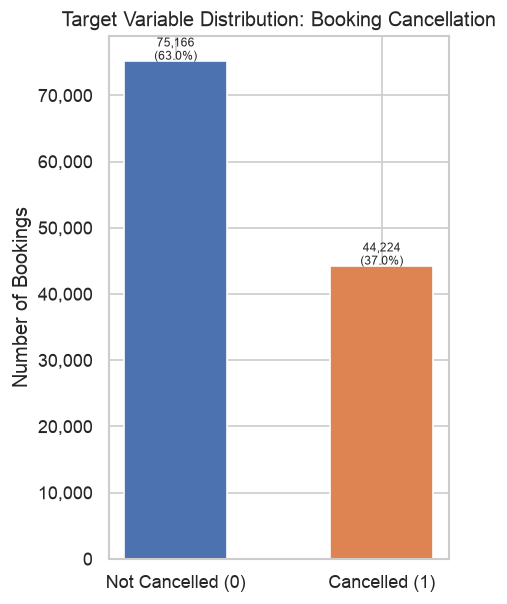

In [6]:
#Inspecting the balance of our binary target variable: is_canceled
target_counts = df_raw['is_canceled'].value_counts()
target_pct    = df_raw['is_canceled'].value_counts(normalize=True) * 100

plt.figure(figsize=(4,4))
#Bar plot - shows distribution of all hotel bookings in the dataset comparing completed versus cancelled bookings.
plt.bar(['Not Cancelled (0)', 'Cancelled (1)'],
        target_counts.values,
        color=['#4C72B0', '#DD8452'], edgecolor='white', width=0.5)

for i, (v, p) in enumerate(zip(target_counts.values, target_pct.values)):
    plt.text(i, v+200, f'{v:,}\n({p:.1f}%)', ha='center', fontsize=7)

plt.title('Target Variable Distribution: Booking Cancellation', fontsize=12)
plt.ylabel('Number of Bookings')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout(rect=[0, 0, 1, 1.3])
plt.show()

**Interpretation:**

* **Majority class is "*Not Cancelled*"** — roughly 6 out of every 10 bookings in the dataset were successfully completed without cancellation, making it the dominant class.

* **Minority class is "*Cancelled*"** — about 4 out of every 10 bookings were cancelled, which is still a significantly large proportion and tells us cancellations are not rare events.

* *A 63/37 split — mildly imbalanced but acceptable. No special resampling is needed as the gap can be managed via Logistic Regression or Random Forest classification models.*

## 1.5 Data Distribution — Numeric Features

**What we do:** draw a histogram for each numeric feature.

**Why:** the shape of each distribution (skew, spikes, long tails) tells us which features contain outliers and which models will struggle (e.g. distance-based models need scaling).

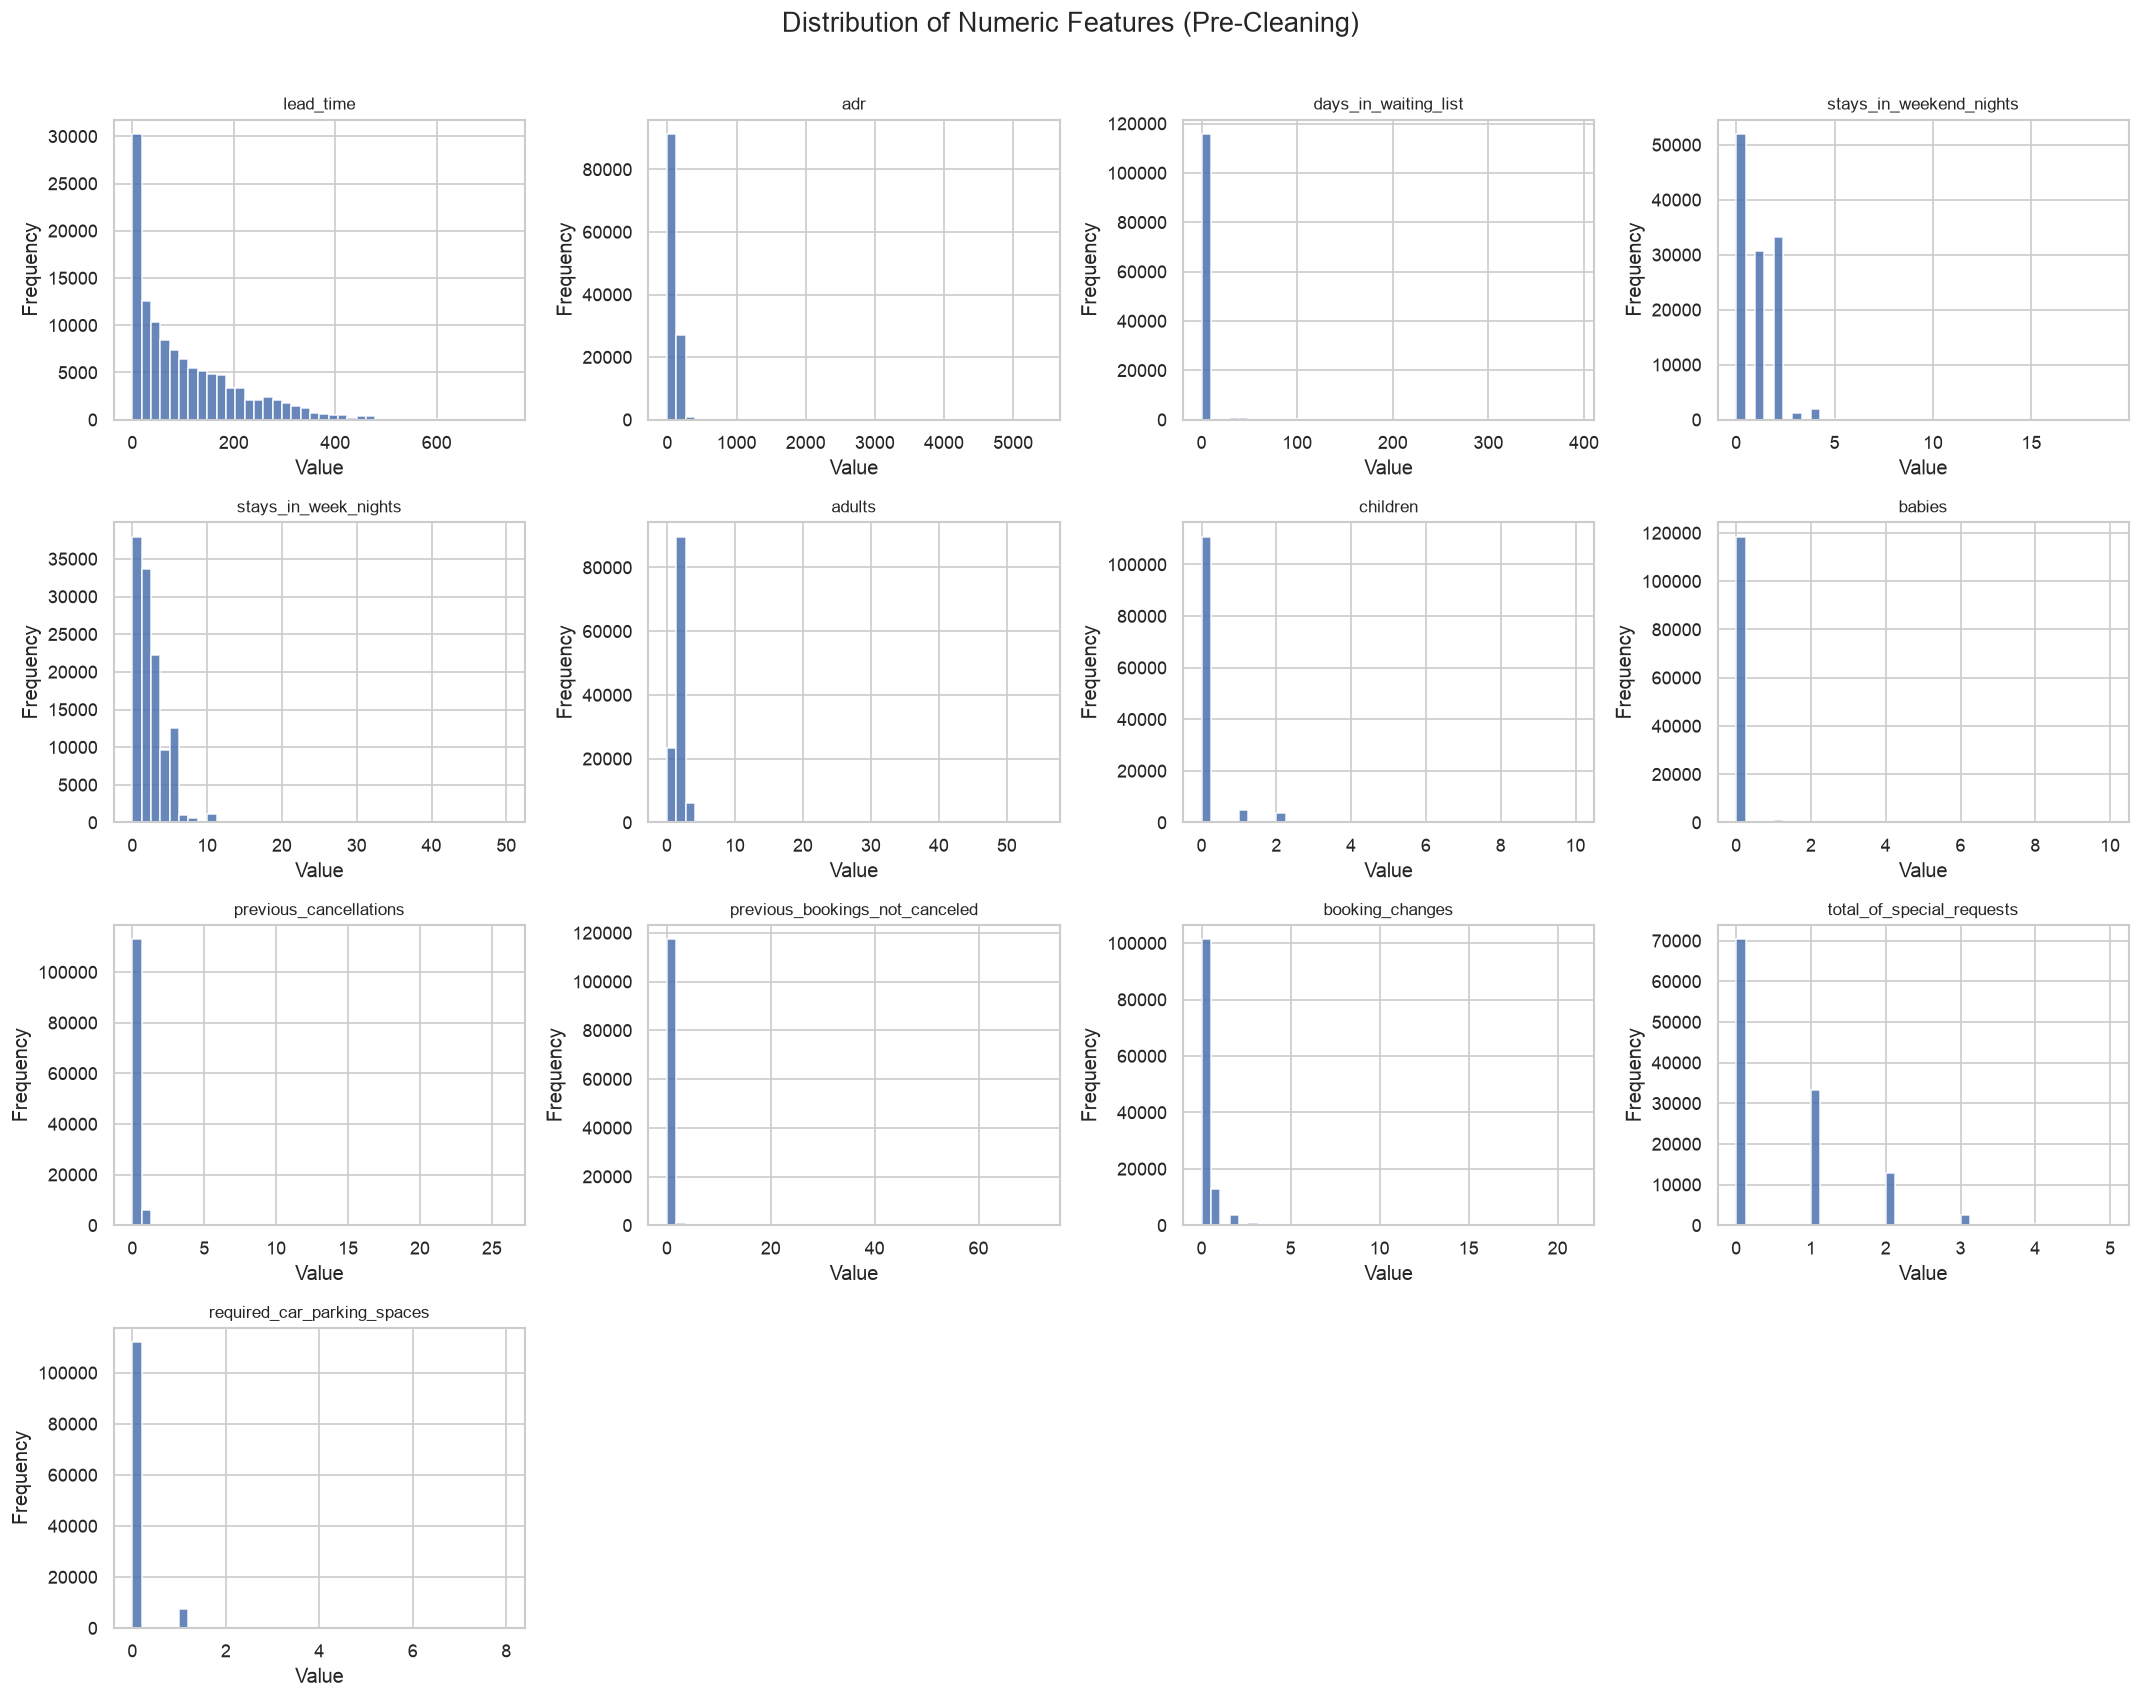

In [7]:
#Histogram plots for all continuous and discrete numeric features - shows skewness, outliers, and distribution shape (normal vs. skewed)

numeric_cols = [
    'lead_time', 'adr', 'days_in_waiting_list',
    'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies',
    'previous_cancellations', 'previous_bookings_not_canceled',
    'booking_changes', 'total_of_special_requests',
    'required_car_parking_spaces'
]

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

#Using equal-width binning for histogram distribution plot.
for i, col in enumerate(numeric_cols):
    axes[i].hist(df_raw[col].dropna(), bins=40, color='#4C72B0', edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

#Hiding unused subplot panels
for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribution of Numeric Features (Pre-Cleaning)', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

**Observations:**

*Right-skewed Features:*

*   lead_time - shows most bookings are either same day or close to arrival day. Further advance bookinsg are lower in number. - P*owerful indicator as more advvanced bookings likely to cancel.*
*   adr - long right trail shows most bookings cluster around low-mid range prices. Possible luxury bookings or outliers may exist.
*   days_in_waiting_list - shows most bookings had zero waiting day, i.e. almost instantly confirmed.

*Zero-Inflated Features:*

*   babies - Almost all values are zero with a tiny value for 1, i.e. bookings with babies are rare.
*   children - Majority bookings have 0 children and small values at 1 & 2.
*   previous_cancellations - shows most guests have never cancelled  before with very small counts at 1, 2 and beyond, suggesting a guest cancelling before may cancel again. - *Powerful attribute for modelling*.
*   previous_bookings_not_canceled - Same pattern — spike at 0, Most guests are first-time or infrequent visitors.
*   booking_changes - Most guests have 0 changes with 1 or 2 changes made for smaller proprotions.

*Moderately Skewed Features*

*   stays_in_weekend_nights - Most stays involve 0–2 weekend nights
*   stays_in_week_nights - Peaks around 1–3 weeknights, slight more spread than weekend night stays.
*   adults - Clear spike at 2 (couples/pairs dominate), Smaller bars at 1 (solo) and 3 (small group). Large group entries are less and 0-adult entries are invalid and should be cleaned.

*Near-Constant Features*

*   total_of_special_requests - Peaks at 0, then decreases at 1, 2, 3. Guests with more special requests less likely to cancel — *useful predictive signal*
*   required_car_parking_spaces - Almost entirely 0 — very few guests requested parking

## 1.6 Data Distribution — Categorical Features

**What we do:** draw bar charts for the categorical features.

**Why:** it shows which categories dominate and which are rare, which guides encoding and shows if a feature carries any signal at all.

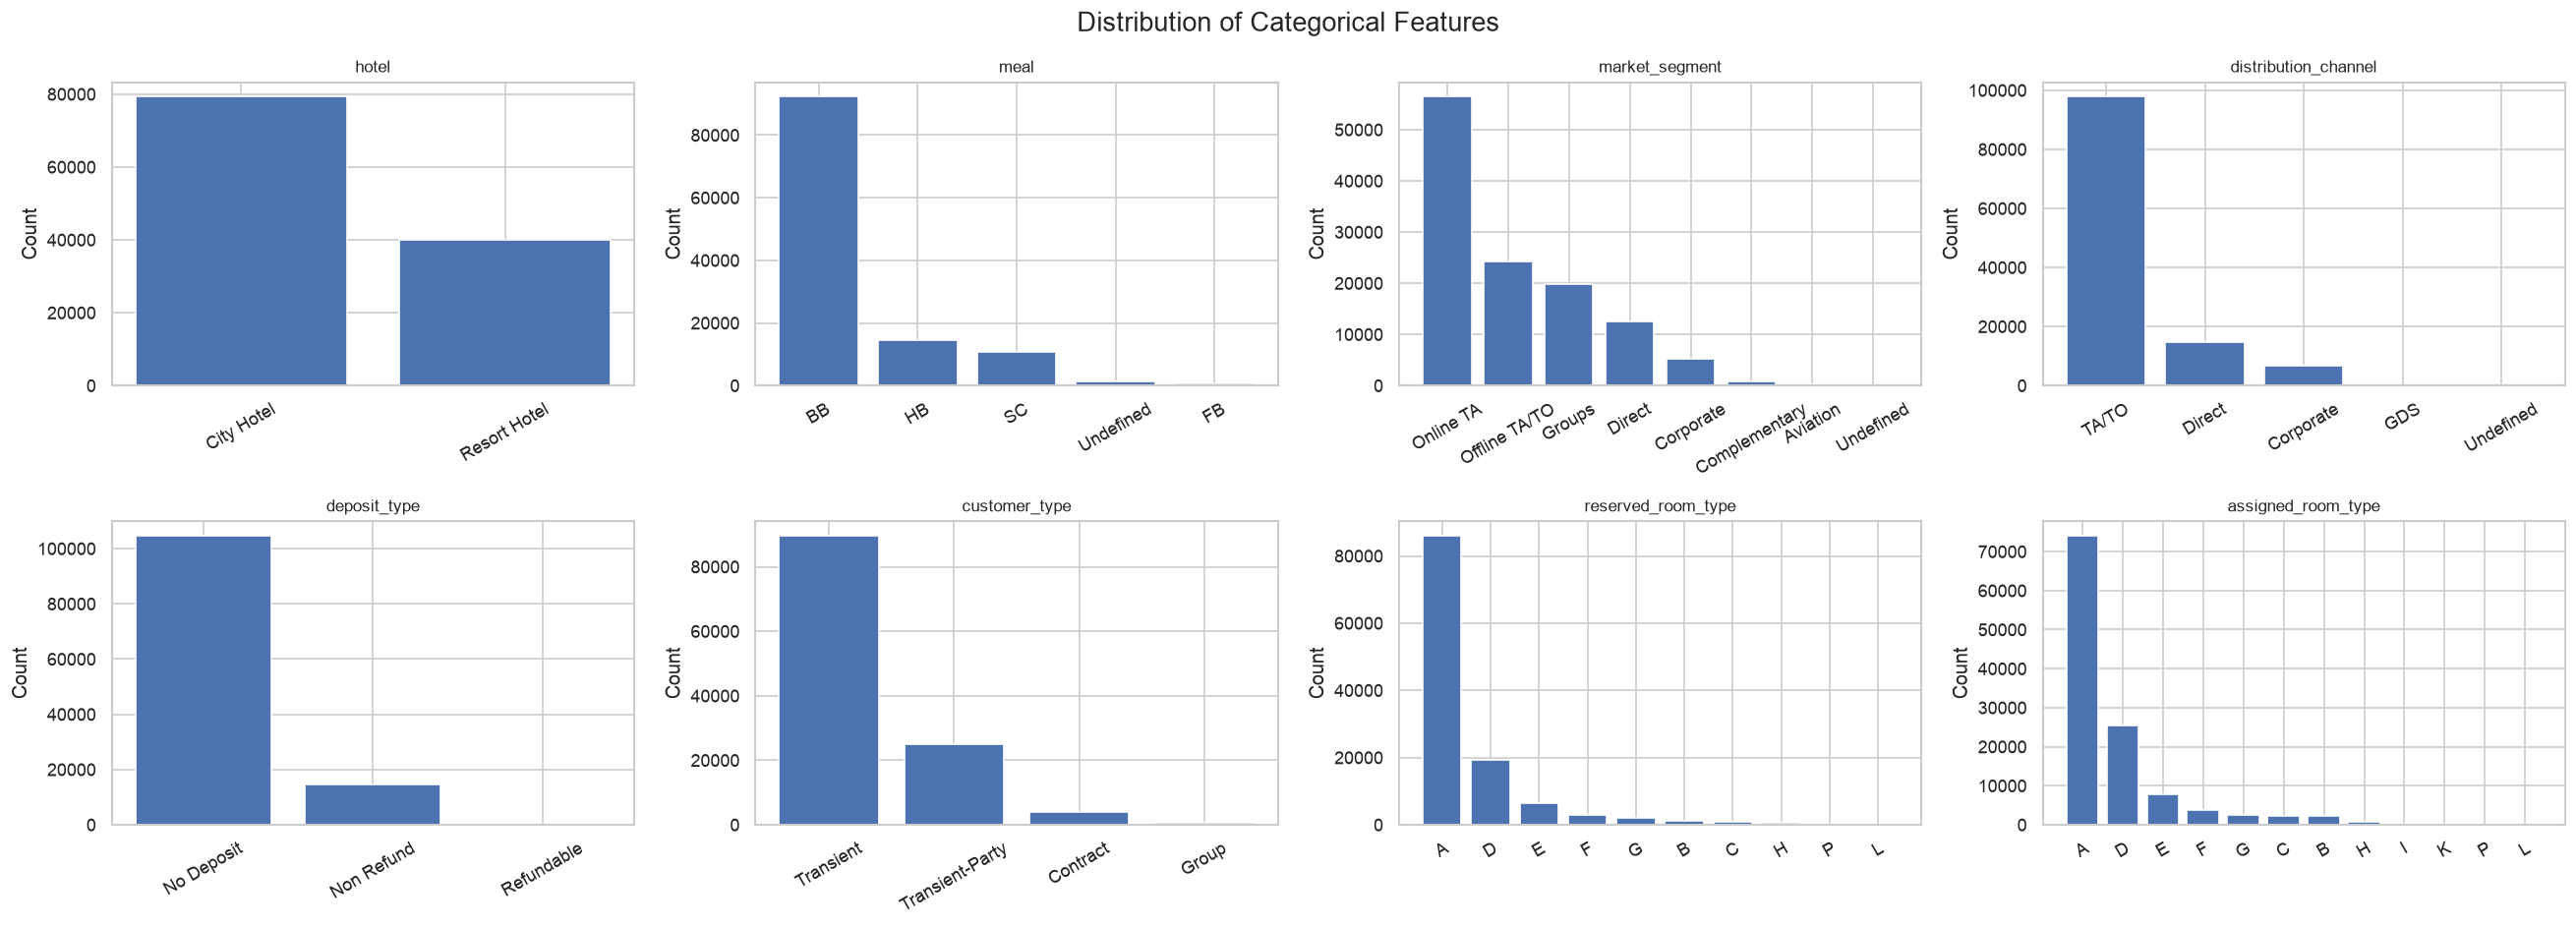

In [8]:
#Bar charts for categorical features - study the spread of categories and spot dominant values
cat_cols = ['hotel', 'meal', 'market_segment', 'distribution_channel',
            'deposit_type', 'customer_type', 'reserved_room_type', 'assigned_room_type']

fig, axes = plt.subplots(2, 4, figsize=(22, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    counts = df_raw[col].value_counts()
    axes[i].bar(counts.index, counts.values, color='#4C72B0', edgecolor='white')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=30)

fig.suptitle('Distribution of Categorical Features', fontsize=16)
plt.tight_layout()
plt.show()

**Observations:**

*   hotel - shows bookinsgs for only 2 hotels with almost twice the bookings in City Hotel in comparison to Resort Hotel.
*   meal - *Categories: BB (Bed & Breakfast), HB (Half Board), FB (Full Board), SC (Self Catering), Undefined* Most guests preferred breakfasts included, very few prefer either half-board or self-catering services, and very little preferring full-board meal services. Undefined category needs cleaning.
*   market-segment - Most bookings made through online travel agencies, with moderate bookings via offline travel agencies or groups. Very few direct and corporate bookings made.
*   distribution-channel- Travel Agencies (TA) & Tour Operators (TO) are most preferred choices, while direct and corporate bookings are small. Resonates with market-segment distribution.
*   deposit-type - No deposit bookings dominate, while few non-refundable bookings also exist. Negligible refundable bookings. - *Likely a contributing factor in booking cancellations.*
*   customer_type - Transient customers - individual short-term bookings dominate. Transient-Party is second (small groups booking together informally)
Contract and Group customers are rare.
*   reserved_room_type - Most reserved room type - A, D and E are moderate; others (B, C, F, G, H, L) are rare.
*   assigned_room_type - Most reserved room type - A, distribution for D and E is more spread than reserved types, *room re-allocation may be an influencing factor for cancellation behaviour.*



## 2. Exploratory Data Analysis

**Objective:** Identify and understand data quality issues — missing values outliers, impossible values, and inconsistencies — before addressing them.

## 2.1 Missing Values


**What we do:** count missing values per column and express them as a percentage.

**Why:** most models cannot accept `NaN`. The percentage tells us whether to impute a column or drop it.

────── Columns with Missing Values ──────
          Missing Count  Missing %
company          112593  94.306893
agent             16340  13.686238
country             488   0.408744
children              4   0.003350


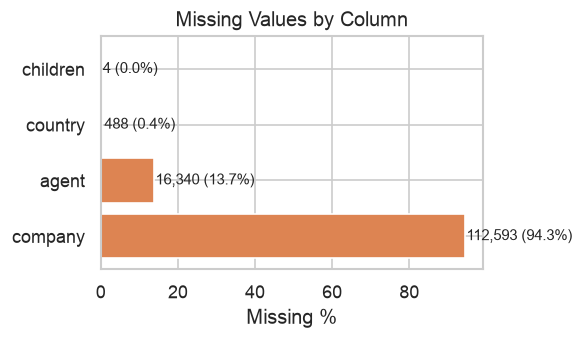

In [9]:
#Shows total missing values per column and its percentage. Higher % of missing values to be addressed.
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw)) * 100

missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print('────── Columns with Missing Values ──────')
print(missing_df)

#Visualise missing values as a horizontal bar chart
plt.figure(figsize=(5,3))
plt.barh(missing_df.index, missing_df['Missing %'], color='#DD8452', edgecolor='white')
for i, (idx, row) in enumerate(missing_df.iterrows()):
    plt.text(row['Missing %'] + 0.5, i,
            f"{int(row['Missing Count']):,} ({row['Missing %']:.1f}%)",
            va='center', fontsize=9)
plt.xlabel('Missing %')
plt.title('Missing Values by Column', fontsize=12)
plt.tight_layout()
plt.show()

**Findings:**
4 attributes have missing values - company, agent, country and children.

*   company  : 94.3% missing → can be DROPPED as values are sparse and as per previous checks most bookings are transient (individual) customers.
*   agent    : 13.7% missing → can be converted to binary value - has_agent.
*   country  : 0.4%  missing → can be replaced with mode (most frequent country)
*   children : <0.1% missing → can be computed as 0 (safe assumption: no children) as very few customers observed travelling with children from above distribution trends.

## 2.2 Outlier Detection — Using Boxplot and IQR Method


**What we do:** draw boxplots and flag outliers with the IQR rule (below Q1 − 1.5×IQR or above Q3 + 1.5×IQR).

**Why:** extreme values distort scale-sensitive models (Logistic Regression, kNN, SVM). We still check each one against domain knowledge before deleting it, because not every statistical outlier is an error.

────── Outlier Summary (IQR Method) ──────

lead_time                      Q1=18.0  Q3=160.0  IQR=142.0  Bounds=[-195.0, 373.0]  Outliers=3,005
adr                            Q1=69.3  Q3=126.0  IQR=56.7  Bounds=[-15.8, 211.1]  Outliers=3,793
days_in_waiting_list           Q1=0.0  Q3=0.0  IQR=0.0  Bounds=[0.0, 0.0]  Outliers=3,698
adults                         Q1=2.0  Q3=2.0  IQR=0.0  Bounds=[2.0, 2.0]  Outliers=29,710


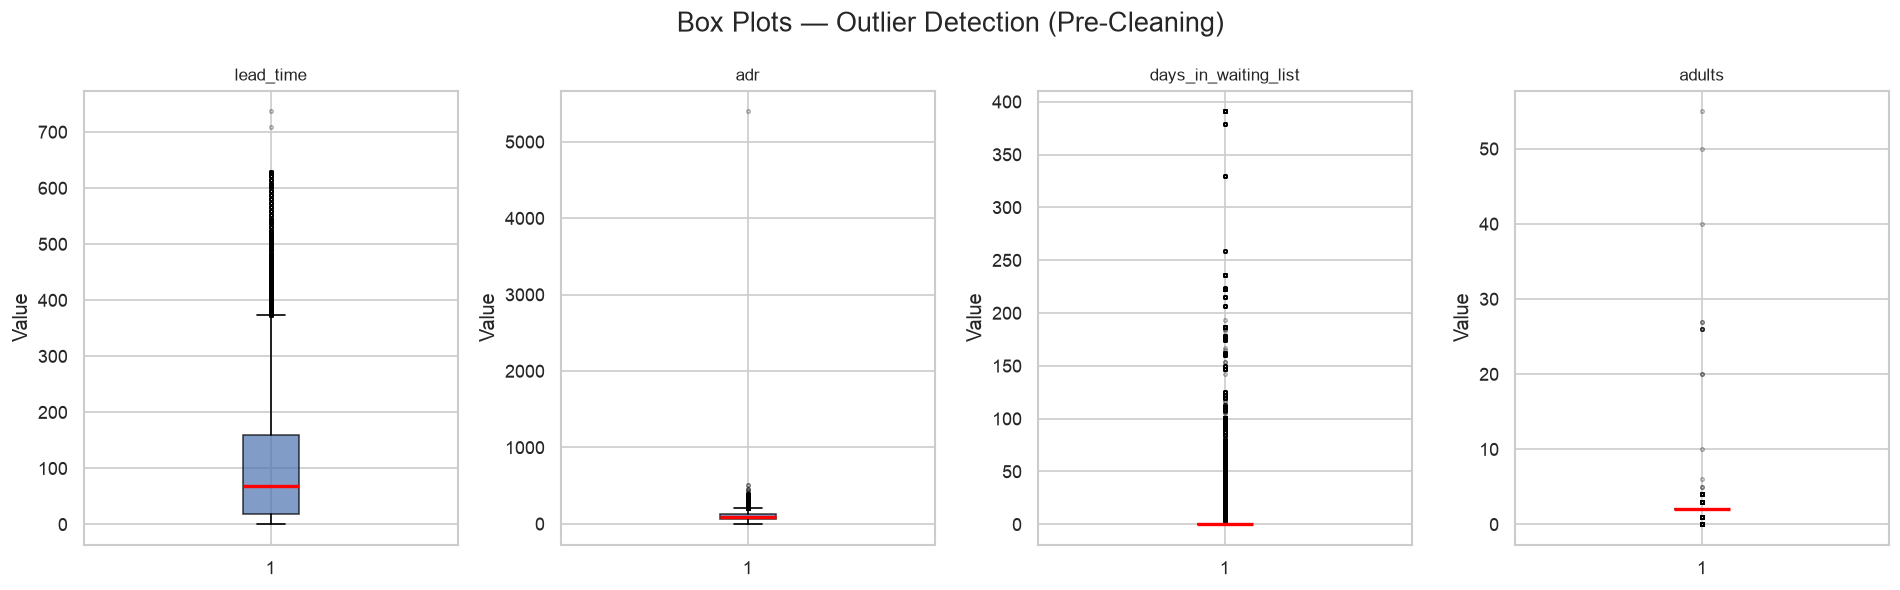

In [10]:
#Outlier detection using IQR
#Value < Q1 - 1.5×IQR or Value > Q3 + 1.5×IQR is flagged as an outlier

outlier_cols = ['lead_time', 'adr', 'days_in_waiting_list', 'adults']

print('────── Outlier Summary (IQR Method) ──────\n')
for col in outlier_cols:
    Q1  = df_raw[col].quantile(0.25)
    Q3  = df_raw[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df_raw[col] < lower) | (df_raw[col] > upper)).sum()
    print(f'{col:<30} Q1={Q1:.1f}  Q3={Q3:.1f}  IQR={IQR:.1f}  '
          f'Bounds=[{lower:.1f}, {upper:.1f}]  Outliers={n_out:,}')

#Visualising outliers using Box Plots
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, col in enumerate(outlier_cols):
    axes[i].boxplot(df_raw[col].dropna(), vert=True, patch_artist=True,
                    boxprops=dict(facecolor='#4C72B0', alpha=0.7),
                    medianprops=dict(color='red', linewidth=2),
                    flierprops=dict(marker='o', color='#DD8452', alpha=0.3, markersize=2))
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('Value')

fig.suptitle('Box Plots — Outlier Detection (Pre-Cleaning)', fontsize=16)
plt.tight_layout()
plt.show()

**Interpretations:**

*   lead time:
      - Lower bound (negative time) is insignificant.
      - Upper bound - Bookings made more than 373 days can be flagged as outliers.
      - Bookings between 373- ~630 days, show advance planners and early guest bookings in advance.
    
*   adr:
      - Lower bound is negative - insignificant.
      - Rates above ~€211 are flagged as statistical outliers.
      - Significant no. of entries between (€211-€500) may reflect luxury bookings. Thus, significat outlier is at €5,400.

*   days_in_waiting_list
      - All parameters Q1, Q3 and IQR reflects 0, i.e. over 75% records had 0 waiting days.
      - Any non-zero waiting day entry is considered as an outlier, i.e. unreliable outcome.

*   adults
      - Q1 & Q3 = 2, since most bookings are for 2 adults.
      - As IQR = 0, any other value is treated as outlier, i.e. 1(solo) and 3(group) bookings.
      - Valid entries may incorrectly be treated as outliers.





## 2.3 Impossible / Inaccurate Values


**What we do:** look for values that are logically impossible (negative price, zero guests, 55 adults, `Undefined` categories).

**Why:** these are data-entry errors, not rare-but-valid events, so they must be cleaned and not just flagged.

In [11]:
#identifying illogical/ impossible values basis generic and domain knowledge
print('────── Checking Impossible Values ──────\n')

#adr (Average Daily Rate) can never be less than 0.
neg_adr = df_raw[df_raw['adr'] < 0]
print(f'Negative ADR values           : {len(neg_adr):>5} rows  (min={df_raw["adr"].min():.2f})')

#Invalid booking - if adults & children & babies = 0, i.e. no guests.
no_guests = df_raw[(df_raw['adults'] == 0) & (df_raw['children'] == 0) & (df_raw['babies'] == 0)]
print(f'Bookings with 0 guests        : {len(no_guests):>5} rows')

#Invalid booking - booking with only children & babies, and zero adults.
no_adult_guests = df_raw[((df_raw['adults'] == 0) & (df_raw['children'] != 0) & (df_raw['babies'] != 0)) | ((df_raw['adults'] == 0) & (df_raw['children'] == 0) & (df_raw['babies'] != 0)) | ((df_raw['adults'] == 0) & (df_raw['children'] != 0) & (df_raw['babies'] == 0))]
print(f'Bookings with 0 guests        : {len(no_adult_guests):>5} rows')

#Adults with extreme values (>10 usually indicate data entry errors for individual bookings)
high_adults = df_raw[df_raw['adults'] > 10]
print(f'adults > 10                   : {len(high_adults):>5} rows  (max={df_raw["adults"].max()})')

#Extremely high ADR outlier
high_adr = df_raw[df_raw['adr'] > 500]          #Using IQR & histogram to determine the threshold as 500
print(f'ADR > 500                     : {len(high_adr):>5} rows  (max={df_raw["adr"].max():.2f})')

#Undefined values in categorical columns are treated as a quality issue
print(f'meal = "Undefined"            : {(df_raw["meal"] == "Undefined").sum():>5} rows')
print(f'market_segment="Undefined"    : {(df_raw["market_segment"] == "Undefined").sum():>5} rows')
print(f'distribution_channel="Undef"  : {(df_raw["distribution_channel"] == "Undefined").sum():>5} rows')

────── Checking Impossible Values ──────

Negative ADR values           :     1 rows  (min=-6.38)
Bookings with 0 guests        :   180 rows
Bookings with 0 guests        :   223 rows
adults > 10                   :    12 rows  (max=55)
ADR > 500                     :     3 rows  (max=5400.00)
meal = "Undefined"            :  1169 rows
market_segment="Undefined"    :     2 rows
distribution_channel="Undef"  :     5 rows


**Findings:**

* 1 row with negative ADR, 3 rows with ADR > 500 (max 5,400) → removed in 3.2.
* 180–223 bookings with zero guests → impossible, removed in 3.2.
* 12 rows with more than 10 adults (max 55) → group bookings or typos; handled by the guest rules and outlier step.
* `Undefined` appears in `meal` (1,169 rows), `market_segment` (2) and `distribution_channel` (5) → replaced with the most frequent value in 3.2.

## 2.4 Inconsistency Check — Reserved vs Assigned Room Type

**What we do:** compare the *reserved* room type with the *assigned* room type and build a binary flag `room_was_changed`.

**Why:** a changed room is a possible signal of service issues or upgrades, and it may influence whether the guest cancels.

In [12]:
#Room upgrades/ downgrades (i.e. reserved vs assigned rooms are different) - impact on customer satiscation and cancellation
room_mismatch = df_raw[df_raw['reserved_room_type'] != df_raw['assigned_room_type']]
print(f'Bookings where room type was changed: {len(room_mismatch):,} '
      f'({len(room_mismatch)/len(df_raw)*100:.1f}% of all bookings)')

#Determining cancellation rate for same room vs different room allotment, by introducing new binary feature - room_was_changed (0 - No change & 1 - Change)
df_raw['room_was_changed'] = (df_raw['reserved_room_type'] != df_raw['assigned_room_type']).astype(int)
print('\nCancellation rate by room change:')
for changed, group in df_raw.groupby('room_was_changed'):
    rate = group['is_canceled'].mean().round(3) * 100
    label = 'Room Changed    ' if changed else 'Room Unchanged  '
    print(f'{label}: {rate:.1f}% cancellation rate')

Bookings where room type was changed: 14,917 (12.5% of all bookings)

Cancellation rate by room change:
Room Unchanged  : 41.6% cancellation rate
Room Changed    : 5.4% cancellation rate


**Findings:**

*   A new feature `room_was_changed` is created by comparing `reserved_room_type` and `assigned_room_type`.
*   Guests who received their requested room cancelled more often — suggesting room change alone does not drive the booking cancellations.
*   However, the gap in cancellation rates between both groups makes this a useful feature for modelling.


## 2.5 Duplicate Checks

**What we do:** count fully duplicated rows.

**Why:** duplicates can leak between train and test sets and inflate scores. We decide whether they are true duplicates or just similar bookings.

In [13]:
#Checking for duplicate records.
print(df_raw.duplicated().sum())

#Checking duplicates count
print(df_raw[df_raw.duplicated(keep=False)]['is_canceled'].value_counts())

31994
is_canceled
1    23451
0    16714
Name: count, dtype: int64


**Observations:**

>While there may be duplicate entries, but due to the lack of a booking id, we cannot drop the duplicate records, as these may denote that the same type of booking could be done by 2 separate guests. Hence, the duplicate records are retained.

##2.6 Booking Cancellations by Category

**What we do:** compute the cancellation rate inside each category of `hotel`, `meal` and `customer_type`.

**Why:** a first look at which groups cancel more, before modelling.


Cancellation Rate by hotel:
              Total Bookings  Cancellations  Cancellation Rate (%)
hotel                                                             
City Hotel             79330          33102                  41.73
Resort Hotel           40060          11122                  27.76


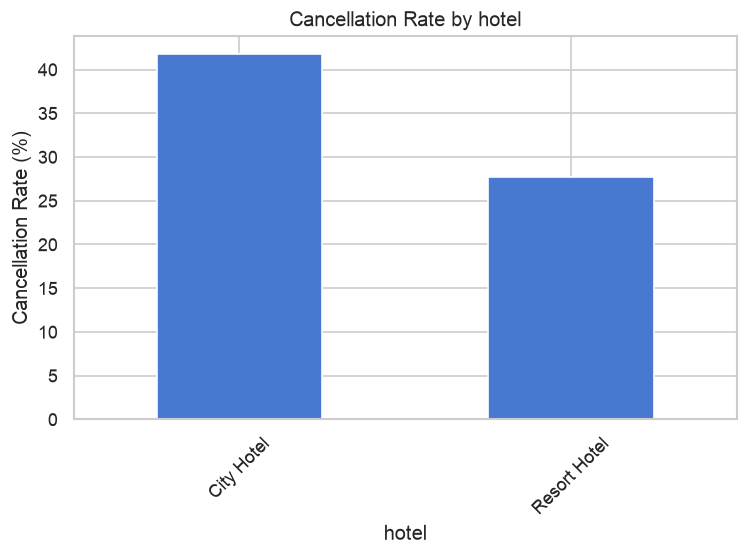


Cancellation Rate by meal:
           Total Bookings  Cancellations  Cancellation Rate (%)
meal                                                           
BB                  92310          34510                  37.38
FB                    798            478                  59.90
HB                  14463           4984                  34.46
SC                  10650           3966                  37.24
Undefined            1169            286                  24.47


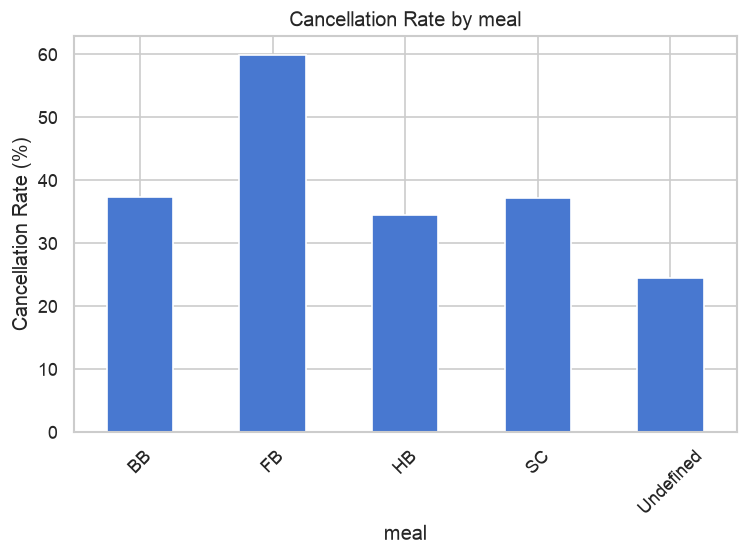


Cancellation Rate by customer_type:
                 Total Bookings  Cancellations  Cancellation Rate (%)
customer_type                                                        
Contract                   4076           1262                  30.96
Group                       577             59                  10.23
Transient                 89613          36514                  40.75
Transient-Party           25124           6389                  25.43


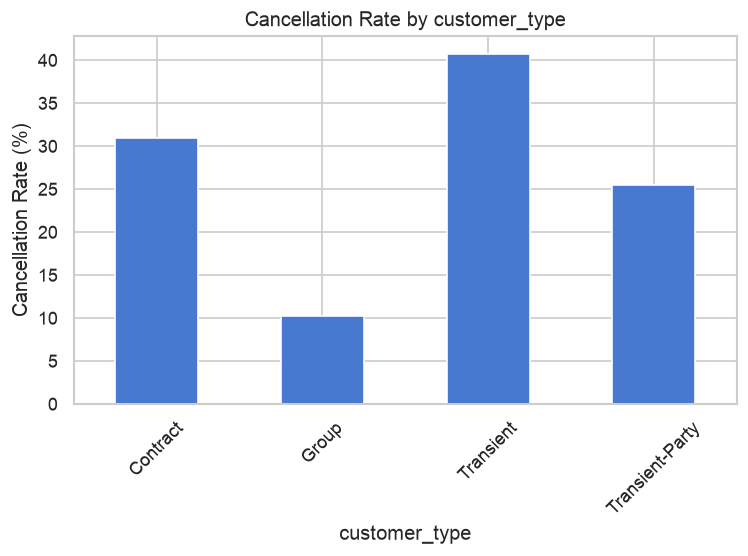

In [14]:
# Cancellation rate by hotel type, etc.
for column in ['hotel', 'meal', 'customer_type']:
    cancellation_by_var = df_raw.groupby(column)['is_canceled'].agg(['count', 'sum', 'mean'])
    cancellation_by_var.columns = ['Total Bookings', 'Cancellations', 'Cancellation Rate (%)']
    cancellation_by_var['Cancellation Rate (%)'] = cancellation_by_var['Cancellation Rate (%)'] * 100

    print(f"\n{'='*70}")
    print(f"Cancellation Rate by {column}:")
    print(f"{'='*70}")
    print(cancellation_by_var.round(2))

    # Visualization
    cancellation_by_var['Cancellation Rate (%)'].plot(kind='bar', title=f'Cancellation Rate by {column}')
    plt.ylabel('Cancellation Rate (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

**Observations:**
* **Hotel type:** City Hotel cancels far more often (41.7%) than Resort Hotel (27.8%), so the two hotels need different overbooking strategies.
* **Meal:** Full Board (FB) bookings have the highest cancellation rate (59.9%), but there are only 798 of them, so this is a small segment. Half Board is lowest among the large groups (34.5%).
* **Customer type:** Transient guests cancel most (40.8%), Contract 31.0%, Transient-Party 25.4%, and Group bookings are the most reliable (10.2%).
* *(These figures come from the raw data, `df_raw`, so the categories are readable labels.)*

## 2.7 Check Class Imbalance

**What we do:** quantify the class ratio numerically.

**Why:** this number drives the decision on SMOTE and on which metrics to report (Precision, Recall, F1, AUC, MCC and not accuracy alone).

In [15]:
print(df_raw['is_canceled'].value_counts(normalize=True))

is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


**Interpretations:**
> The class ratio is 63 % / 37 % — this is actually a moderate class imbalance, not extreme.
Majority class = 0 (not canceled) | Minority class = 1 (canceled)
Using a simple model for prediciton of “not canceled” would always already give a ~63% acuracy. So using accuracy alone for predictions would be misleading.

## 3. Data Preprocessing

**Objective:** Clean and transform the datset- handling missing values, removing impossible records, encoding categoricals, scaling numerics, and feature creation/ selection.

Pipeline order in this section: copy raw data → drop leakage/sparse columns → impute missing values → remove impossible records → remove outliers → encode categories → discretise `lead_time` → engineer features → correlation check → freeze the modelling table.

Every operation is applied to the copy `df`, never to `df_raw`.

In [16]:
#Using a copy of the original dataset for preprocessing and modelling tasks.
df = df_raw.copy()

#Dropping the reservation status and reservation status date as the infirmation will not be fed to the model during training and testing phase.
df.drop(columns=['reservation_status', 'reservation_status_date'], inplace=True)

#Dropping company column as it has too many null values and the transient guest category builds the majority.
df.drop(columns=['company'], inplace=True)

print(f'Shape after dropping leakage/sparse columns: {df.shape}')

Shape after dropping leakage/sparse columns: (119390, 30)


## 3.1 Handling Missing Values

**What we do:** handle the missing values found in 2.1 (`children`, `country`, `agent`).

**Why:** each column gets the imputation that makes business sense: 0 for *no children* and *no agent*, and the most frequent value for `country`. A blanket mean/median fill would be wrong for ID-like columns.

In [17]:
#── children: 4 missing values ───────────────────────────────────────────────
#Assuming no record means no children were in the booking
df['children'] = df['children'].fillna(0).astype(int)

#── country: 488 missing values ──────────────────────────────────────────────
#Replacing with most frequent country (mode) - dominant value
df['country'] = df['country'].fillna(df['country'].mode()[0])

#── agent: 16,340 missing values ─────────────────────────────────────────────
#Using 0 value considering the bookings were made without an agent referral.
df['agent'] = df['agent'].fillna(0).astype(int)

#Verifying no missing values still present
remaining_missing = df.isnull().sum().sum()
print(f'Total missing values after replacements: {remaining_missing}')

Total missing values after replacements: 0


**Interpretations:**
* All missing values in the children, and agent column have been replaced with 0 value, assuming that during the booking either no children were present or that the bookings were all made directly by the guests.
* The mising values in country column have been replaced with the first most dominant country identified using the mode of the given data.



## 3.2 Remove Impossible / Inaccurate Records

**What we do:** delete records that are logically impossible: negative or extreme ADR, bookings with no guests, and bookings with children or babies but no adult (the rule is `adults > 0`). `Undefined` categories are replaced by the most frequent value.

**Why:** these rows are noise. Keeping them would teach the models patterns that cannot exist in real bookings.

In [18]:
initial_rows = len(df)

#Removing negative ADR bookings - impossible rate for hotel bookings
df = df[df['adr'] >= 0]

#Removing bookings where ADR > 4000 — extreme outlier
df = df[df['adr'] <= 4000]       #Threshold derived from IQR & Boxplot reviews.

#Removing bookings with no guests (adult, children, babies = 0) - invalid record
df = df[~((df['adults'] == 0) & (df['children'] == 0) & (df['babies'] == 0))]

#Removing bookings with no adults but only either children or babies or both - practically invalid records.
df = df[df['adults'] > 0]
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

#Replacing 'Undefined' in categorical columns with the mode of that column
for col in ['meal', 'market_segment', 'distribution_channel']:
    df[col] = df[col].replace('Undefined', df[col].mode()[0])

removed = initial_rows - len(df)
remaining = len(df)
print(f'Rows removed during quality cleaning: {removed:,}')
print(f'Remaining dataset size: {remaining:,} rows')

Rows removed during quality cleaning: 405
Remaining dataset size: 118,985 rows


**Interpretations:**
* Only positive rates are retained in dataset, since ADR (Average Daily Rate) price rates can never be physically negative.
* ADR outliers determined by selecting an upper threshold considering IQR and Boxplot was handled. Only value removed ~5,400, since all other values > IQR were considered as reasonable luxury booking rates.
* All invalid bookings with no guests (adults = children = babies = 0) were dropped.
* Also all bookings consisting of only children and/or babies without presence of adults were dropped.
* Undefined value in meal, market_segment & distribution_channel attibutes were replaced with dominant value of the respective attributes using modal value calculation.

## 3.3 Removing Outliers


**What we do:** remove lead times above 730 days and bookings with 0 total nights; this step also creates `total_stay_nights`.

**Why:** a booking made more than two years ahead, or a stay of zero nights, is not a realistic booking, so these rows would only stretch the feature scales.

In [19]:
#Dropping the outlier records
#Lead_time beyond 2 years (730 days) is beyond any realistic booking window
df = df[df['lead_time'] <= 730]

#Combining weekend and weekday nights into a single total stay duration feature
#Checking total_stay_nights should be > 0 nights.
df['total_stay_nights'] = df['stays_in_week_nights'] + df['stays_in_weekend_nights']
df = df[df['total_stay_nights'] > 0]

removed = remaining - len(df)
remaining = len(df)
print(f'Rows removed during quality cleaning: {removed:,}')
print(f'Remaining dataset size: {remaining:,} rows')
print(f'Shape of dataset: {df.shape}')

Rows removed during quality cleaning: 645
Remaining dataset size: 118,340 rows
Shape of dataset: (118340, 31)


**Interpretations:**

* Considering, 2 years as a substantial duration for advance bookings, all records > 730 days lead_time were discarded.
* Week & weekend nights stayed by a guest were combined to represent total_nights_stay, which should be > 0 (meaning guests stayed atleast 1 day). All other records were discarded.
* Revised dataset view post cleaning the missing, inaccurate and outlier records, has 118340 rows and 31 columns.

## 3.4 Encoding Categorical Values


**What we do:** convert text columns into numbers: `LabelEncoder` for nominal columns, and a month-order mapping for `arrival_date_month`.

**Why:** scikit-learn models need numeric input. Months are mapped in calendar order so the model can see that December follows November.

In [20]:
# ── Strategy ──────────────────────────────────────────────────────────────────
# ── Encode all nominal categorical columns ──────────────────────────
le = LabelEncoder()

cat_cols = [
    'hotel', 'meal', 'country', 'market_segment',
    'distribution_channel', 'deposit_type', 'customer_type',
    'reserved_room_type', 'assigned_room_type'
]

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

print(f'Shape after nominal encoding: {df.shape}')
print(f'All nominal dtypes numeric: {df[cat_cols].select_dtypes(include="object").shape[1] == 0}')


# ── Handle arrival_date_month separately with ordinal mapping ────────
# This preserves the temporal order (January < February < ... < December)
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

le_month = LabelEncoder()
le_month.fit(month_order)

df['arrival_date_month_encoded'] = le_month.transform(df['arrival_date_month']) + 1

# ── Create derived year-month feature ────────────────────────────────
df['arrival_year_month'] = (df['arrival_date_year'] * 100) + df['arrival_date_month_encoded']

# Final validation
print(f'\nFinal shape: {df.shape}')
print(f'All numeric: {len(df.select_dtypes(include="object").columns) == 0}')

Shape after nominal encoding: (118340, 31)
All nominal dtypes numeric: True



Final shape: (118340, 33)
All numeric: False


**Interpretations:**
> All categorical (nominal & ordinal attributes) & date-type attributes are converted into numeric values, as ML models only work with numeric values.

**Note on this encoding choice:** `LabelEncoder` gives each category an arbitrary integer, which implies an order and distances that do not exist (for example `country` has 177 categories). This hurts linear and distance-based models (Logistic Regression, kNN, SVM) more than trees. One-hot encoding would remove the problem, but the nine encoded columns would turn into about 226 columns (`country` alone adds 177), which slows RFE, hurts kNN and SVM in high dimensions, and makes the app's input file much wider. We therefore keep label encoding for all models and state it as a limitation in section 12; the Decision Tree is unaffected by it.

## 3.5 Data Discretization

**What we do:** bin `lead_time` into six business-friendly urgency buckets (Same Day … Very Far in Advance) using fixed-width bins.

**Why:** buckets are easier to explain to a hotel manager. The result is a ready-made ordinal feature, and the bar chart checks that no bucket is empty.


                    Booking Urgency                


lead_time_binned
Same Day                9383
Last Minute             9845
Short Notice           18821
Planned                29382
Well in Advance        26330
Very Far in Advance    24579
Name: count, dtype: int64


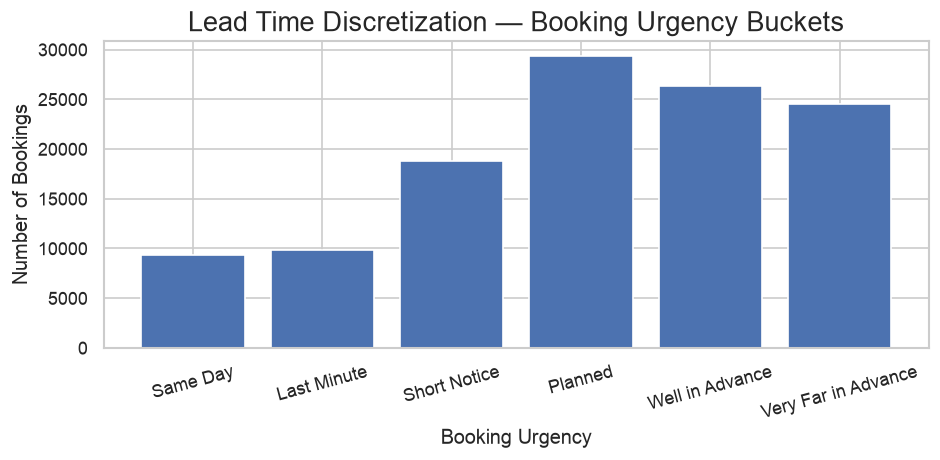

In [21]:
print('===================================================\n')
print('                    Booking Urgency                \n')
print('===================================================\n')
#Converting the original lead_time values to represent using inferred labels.
#Only used for discrete values - not required in the final modeling dataset.
bins   = [0, 1, 7, 30, 90, 180, 730]
labels = ['Same Day', 'Last Minute', 'Short Notice',
          'Planned', 'Well in Advance', 'Very Far in Advance']

df['lead_time_binned'] = pd.cut(df['lead_time'], bins=bins,
                                labels=labels, include_lowest=True)

#Count of bookings per bucket
bin_counts_booking = df['lead_time_binned'].value_counts().sort_index()
print(bin_counts_booking)

#Bar chart showing distribution across buckets
plt.figure(figsize=(8, 4))
plt.bar(bin_counts_booking.index.astype(str), bin_counts_booking.values, color='#4C72B0', edgecolor='white')
plt.title('Lead Time Discretization — Booking Urgency Buckets').set_fontsize(16)
plt.xlabel('Booking Urgency').set_fontsize(12)
plt.ylabel('Number of Bookings')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Interpretations:**
* As the lead time is a continuous numeric attribute, using the Equal Width Binning technique, the lead_time is discretized into labels that reflect the booking period in terms of the relative time taken for making the bookings.
* Booking Urgency bar chart reflects that majority of the bookings were well planned with time or in advance, with fewer bookings made on the same day or at last minute.
* ADR/total guest bookinsg is discretized using the Equal Width Binning technique into labels that reflect the booking costs/ no. of guests into Booking Segmentations.
* Booking Segmentation bar chart reflects that majority bookings are in Economhy and Mid classes and the lowest bookings in the Luxury segment.

## 3.6 Feature Engineering - Derived Features

**What we do:** create new features from existing columns (stay length, weekend ratio, total guests, children flags, season flags, guest cancellation rate).

**Why:** several raw columns say the same thing in pieces. Combining them gives the models stronger, less redundant signals and reduces column count.

In [22]:
#── 1. Total Stay Length ──────────────────────────────────────────────────────
#Introduced total_stay_nights = stay_in_week_nights + stay_in_weekend_nights during outlier handling.

#── 2. Weekend ratio ──────────────────────────────────────────────────────
#Introduced weekend_ratio = stay_in_week_nights / stay_in_weekend_nights + 1.
df['weekend_ratio'] = df['stays_in_weekend_nights'] / (df['total_stay_nights'] + 1)
df.drop(columns=['stays_in_week_nights', 'stays_in_weekend_nights'], inplace=True)

#── 3. Room Was Changed ───────────────────────────────────────────────────────
#room_was_changed attribute created during data quality checks.
# 1 = different room allocated, 0 = same room allocated
df.drop(columns=['reserved_room_type', 'assigned_room_type'], inplace=True)

#── 4. Total Guests ───────────────────────────────────────────────────────────
#Combining adults, children, and babies into a single guest count feature
df['total_guests'] = df['adults'] + df['children'] + df['babies']

#── 5. Guests with Children ───────────────────────────────────────────────────────────
#Introduced new column for guest with children or babies > 0 and further identifying no of children per adult.
df['has_children'] = ((df['children'] > 0) | (df['babies'] > 0)).astype(int)
df['children_per_adult'] = df['children'] / (df['adults'] + 1)
df.drop(columns=['adults', 'children', 'babies'], inplace=True)

#── 6. Arrival Period & Seasonality ───────────────────────────────────────────────────────────
#Mapping month value to numeric format during LabelEncoding and dropped the redundant columns
#Also identified seasonality of months for bookings
df['is_summer'] = df['arrival_date_month_encoded'].isin([6, 7, 8]).astype(int)  # June, July, August
df['is_winter'] = df['arrival_date_month_encoded'].isin([12, 1, 2]).astype(int)  # Dec, Jan, Feb
df.drop(columns=['arrival_date_month','arrival_date_week_number',
                 'arrival_date_day_of_month'], inplace=True)

#── 7. Lead time binned(encoded)) ─────────────────────────────────────────────
df['lead_time_binned_code'] = df['lead_time_binned'].cat.codes
df.drop(columns=['lead_time_binned'], inplace=True)

#── 8. Guest Cancel Rate (historical cancellations) ───────────────────────────
#Total historical bookings for each guest
df['total_previous_bookings'] = df['previous_cancellations'] + df['previous_bookings_not_canceled']

#Calculating a guest's historical cancellation rate
#0 - first time guest & 1 - frequent cancellers (hish risk guests)
df['guest_cancel_rate'] = np.where(
    df['total_previous_bookings'] > 0,
    df['previous_cancellations'] / df['total_previous_bookings'],
    0
)

df.drop(columns=['previous_cancellations', 'previous_bookings_not_canceled', 'total_previous_bookings','market_segment'], inplace=True)

print(f'\nDataset shape after feature engineering: {df.shape}')
print('New derived features added:')
print('  • total_stay_nights')
print('  • room_was_changed')
print('  • total_guests')
print('  • arrival_year_month')
print('  • guest_cancel_rate')
print(f'\nDataset shape after feature engineering: {df.shape}')



Dataset shape after feature engineering: (118340, 28)
New derived features added:
  • total_stay_nights
  • room_was_changed
  • total_guests
  • arrival_year_month
  • guest_cancel_rate

Dataset shape after feature engineering: (118340, 28)


**Interpretations:**
* total_stay_nights = stay_in_week_nights + stay_in_weekend_nights - Represents total nights stayed by a guest.
* room_was_changed - Compares the reserved vs assigned room type for a guest.
* total_guests - Represents the total no. of adults, children & babies staying in a single booking.
* arrival_year_month - Shows the month and year during which the guest supposedly arrives for the booking.
* lead_time_binned - Only created to represent the simplistic view of the advance booking time.
* guest_cancel_rate - Derived from previous_cancellations & previous bookings not cancelled by a guest and completed successfully to determine, if a guest is high risk or not.

## 3.7 Correlation heat map

**What we do:** plot the correlation matrix of all numeric features.

**Why:** it shows which features move with the target and which pairs are redundant with each other (multicollinearity hurts Logistic Regression coefficients).

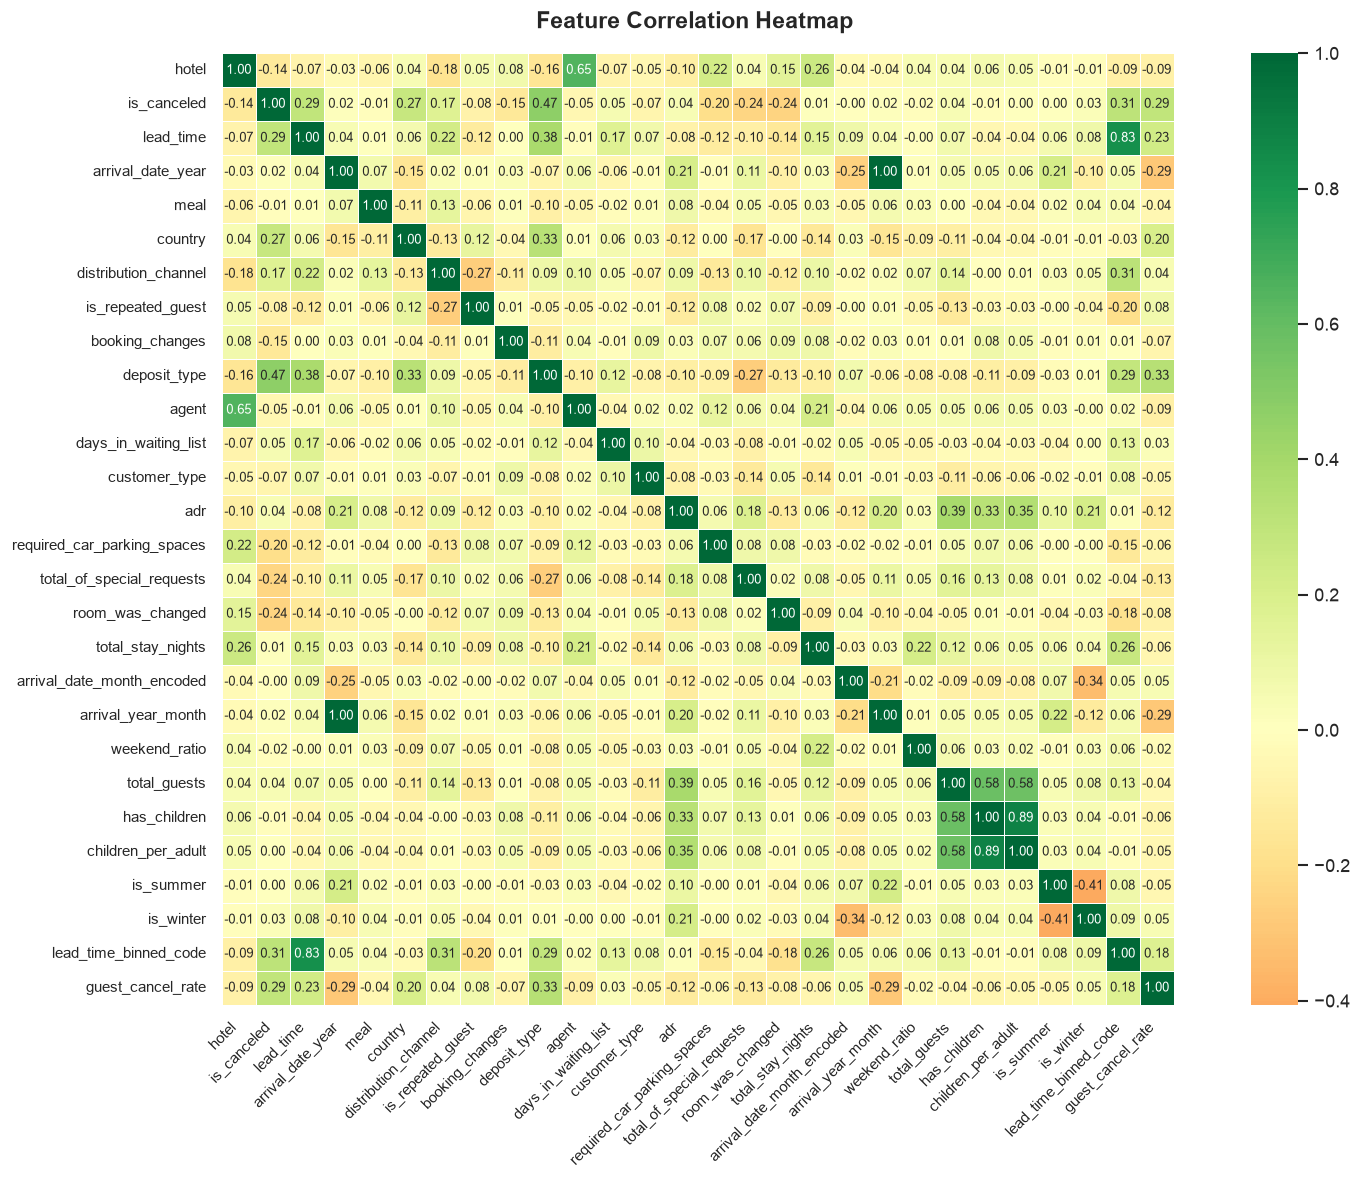

In [23]:
# Correlation heatmap
plt.figure(figsize=(14, 10))

corr_matrix = df.corr()

sns.heatmap(
    corr_matrix,
    annot      = True,
    fmt        = '.2f',
    cmap       = 'RdYlGn',
    center     = 0,
    linewidths = 0.5,
    linecolor  = 'white',
    square     = True,
    annot_kws  = {'size': 8}
)

plt.title('Feature Correlation Heatmap ',
          fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
#plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations:**
>The heatmap shows that the correlation is mostly weak to moderate. Deposit_type remains the most strongly correlated feature with cancellation, followed by lead_time_binned_code, guest_cancel_rate and country. Prices have no impact on the cancellation decisions. Negative correlations are observed with total_of_special_requests, room_was_changed and requred_car_parking_spaces, acting as protective factors. Overall, the dataset suggests non-linear relationships, no dominant feature present and no multicollinearity issues, thus, making decision tree-based models more suitable.

## 3.8 Preprocessed Dataset Summary

**What we do:** split the cleaned table into the feature matrix `x` (27 columns) and the target `y`, and re-check dtypes and missing values.

**Why:** this is the final sanity check before modelling: all-numeric, no `NaN`, and the class ratio is known.

In [24]:
#Separating selection features(x) from the target variable (y)
x = df.drop(columns=['is_canceled'])
y = df['is_canceled']

print(f'Feature matrix (x): {x.shape}')
print(f'Target vector  (y): {y.shape}')
print(f'\nClass distribution in cleaned dataset:')
print(y.value_counts())
print(f'\nAll values numeric: {x.select_dtypes(include="object").shape[1] == 0}')
print(f'Missing values: {x.isnull().sum().sum()}')

print("\n\nBefore SMOTE:")
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

Feature matrix (x): (118340, 27)
Target vector  (y): (118340,)

Class distribution in cleaned dataset:
is_canceled
0    74249
1    44091
Name: count, dtype: int64

All values numeric: True
Missing values: 0


Before SMOTE:
is_canceled
0    74249
1    44091
Name: count, dtype: int64
is_canceled
0    0.627
1    0.373
Name: proportion, dtype: float64


**Interpretations:**

* After cleaning we keep **118,340 rows × 27 features** (plus the target).
* All values are numeric and there are **no missing values**, so the data can go straight into scikit-learn.
* Class split after cleaning: 74,249 not cancelled (62.7%) and 44,091 cancelled (37.3%). The imbalance is still moderate, which motivates SMOTE in 4.2.

## 4. Model Building: Decision Tree Classifier



---
**Protocol shared by all five models.** To keep the comparison fair, every model uses the same stratified 80/20 split (`random_state=42`), the same SMOTE-balanced training set, the same 16 RFE-selected features, and is scored on the same untouched test set. Section 4 builds this foundation with the Decision Tree; Sections 5–8 add Logistic Regression, kNN, Gaussian Naive Bayes and SVM on top of it; Section 9 compares all of them.

## 4.1 Train / Test Split

80 % training · 20 % testing · stratified to preserve class proportions.

**What we do:** split the data 80% train / 20% test with `stratify=y`.

**Why:** the test set must stay unseen until the final evaluation. Stratifying keeps the 63/37 class ratio identical in both parts.

In [25]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training samples : {x_train.shape[0]}")
print(f"Testing  samples : {x_test.shape[0]}")
print(f"Features         : {x_train.shape[1]}")

Training samples : 94672
Testing  samples : 23668
Features         : 27


**Interpretations:**

* 94,672 rows go to training and **23,668 rows** to testing (80/20).
* Stratification keeps both parts at the same ~37% cancellation rate, so test metrics are comparable with the training distribution.

## 4.2 Fixing Class Imbalance Issue

**What we do:** apply SMOTE (Synthetic Minority Over-sampling) to the **training** set only.

**Why:** cancellations are the 37% minority, so models tend to under-predict them. SMOTE creates synthetic minority examples until both classes are equal. It is never applied to the test set, because real-world data is not balanced and the test result must stay honest.

In [26]:
# Apply SMOTE only on training data — NEVER on test data
sm = SMOTE(random_state=42)
x_train_balanced, y_train_balanced = sm.fit_resample(x_train, y_train)

print("\nAfter SMOTE (training only):")
print(pd.Series(y_train_balanced).value_counts())
print(pd.Series(y_train_balanced).value_counts(normalize=True).round(3))

# x_test stays completely untouched — real world data is never balanced
print(f"\nx_train_balanced shape : {x_train_balanced.shape}")
print(f"x_test shape             : {x_test.shape}  ← never touched")


After SMOTE (training only):
is_canceled
0    59399
1    59399
Name: count, dtype: int64
is_canceled
0    0.5
1    0.5
Name: proportion, dtype: float64

x_train_balanced shape : (118798, 27)
x_test shape             : (23668, 27)  ← never touched


**Interpretations:**

* Before SMOTE the training set has 59,399 not-cancelled vs 35,273 cancelled bookings. After SMOTE both classes have **59,399** rows (118,798 in total), i.e. a perfect 50/50 split.
* The test set (23,668 rows) is untouched, and still has the real 63/37 mix.
* Trade-off: SMOTE adds synthetic points, so cross-validation scores on the training data are slightly optimistic. The test set is the honest number.

## 4.3 Feature Selection with RFE

**Objective:** Keep top 16 features and eliminate others

**What we do:** run Recursive Feature Elimination (RFE) with a Decision Tree as the estimator to keep the 16 most useful of the 27 features.

**Why:** fewer features means faster models, less noise, and easier explanation. The assignment requires at least 12 features, and 16 satisfies it.

In [27]:
#Reducing the features count using #RFE (Recursive Feature Elimination). Let's start with 12 and then tune it.
# Base estimator for RFE (lightweight tree)
rfe_estimator = DecisionTreeClassifier(random_state=42)

rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=16,
    step=2,
    verbose=1
)

# Fit RFE on balanced training data ONLY
rfe.fit(x_train_balanced, y_train_balanced)

# See which features were selected
feature_ranking = pd.DataFrame({
    'Feature' : x_train.columns,
    'Selected': rfe.support_,
    'Ranking' : rfe.ranking_
}).sort_values('Ranking')

print(feature_ranking.to_string(index=False))

Fitting estimator with 27 features.


Fitting estimator with 25 features.


Fitting estimator with 23 features.


Fitting estimator with 21 features.


Fitting estimator with 19 features.


Fitting estimator with 17 features.


                    Feature  Selected  Ranking
required_car_parking_spaces      True        1
               total_guests      True        1
              weekend_ratio      True        1
         arrival_year_month      True        1
 arrival_date_month_encoded      True        1
          total_stay_nights      True        1
           room_was_changed      True        1
  total_of_special_requests      True        1
                        adr      True        1
              customer_type      True        1
          guest_cancel_rate      True        1
                      agent      True        1
               deposit_type      True        1
            booking_changes      True        1
                    country      True        1
                  lead_time      True        1
       distribution_channel     False        2
      lead_time_binned_code     False        3
                       meal     False        3
          arrival_date_year     False        4
             

**RFE picked 16 features** (from 27). The assignment needs at least 12, and 16 satisfies it. The tuned tree reaches about 85% accuracy with them. The least important of them contribute almost nothing to the tree (see the importance chart in 4.10), so a 12-feature model would probably perform about the same, but we keep the features RFE selected so that every model uses one common feature set.

## 4.4 Find the best features to use for model building


**What we do:** read the names of the features RFE kept and build the reduced train/test matrices (`x_train_selected`, `x_test_selected`).

**Why:** all five models, and the Streamlit app, must use exactly this feature list in exactly this order.

In [28]:
# Extract selected feature names
selected_features = x_train.columns[rfe.support_].tolist()
print(f"Selected features ({len(selected_features)}):")
print(selected_features)

Selected features (16):
['lead_time', 'country', 'booking_changes', 'deposit_type', 'agent', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'room_was_changed', 'total_stay_nights', 'arrival_date_month_encoded', 'arrival_year_month', 'weekend_ratio', 'total_guests', 'guest_cancel_rate']


**Interpretations:**

* RFE kept **16 of 27 features**: `lead_time`, `country`, `booking_changes`, `deposit_type`, `agent`, `customer_type`, `adr`, `required_car_parking_spaces`, `total_of_special_requests`, `room_was_changed`, `total_stay_nights`, `arrival_date_month_encoded`, `arrival_year_month`, `weekend_ratio`, `total_guests`, `guest_cancel_rate`.
* Dropped: `distribution_channel`, `lead_time_binned_code`, `meal`, `arrival_date_year`, `is_summer`, `children_per_adult`, `is_winter`, `is_repeated_guest`, `hotel`, `has_children`, `days_in_waiting_list`. Their information is mostly covered by the features that were kept.
* 16 ≥ 12, so the assignment's minimum feature requirement is satisfied.

In [29]:
# Selected Dataset after SMOTE
x_train_selected = x_train_balanced[selected_features]
x_test_selected  = x_test[selected_features]
y_train_selected = y_train_balanced
y_test_selected  = y_test

print(f"\nx_train_selected shape : {x_train_selected.shape}")
print(f"x_test_selected  shape : {x_test_selected.shape}")
print(f"y_train_selected shape : {y_train_selected.shape}")
print(f"y_test_selected  shape : {y_test_selected.shape}")


x_train_selected shape : (118798, 16)
x_test_selected  shape : (23668, 16)
y_train_selected shape : (118798,)
y_test_selected  shape : (23668,)


## 4.5 Baseline Decision Tree (Untuned)

Default DecisionTreeClassifier: no depth limit, no regularisation.

**What we do:** train a first Decision Tree with sensible but untuned settings, and evaluate it on the test set.

**Why:** a baseline gives us a number to beat. If tuning does not improve on it, tuning was not worth the effort.

In [30]:
# Build model on selected features
dt = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
    # No class_weight needed — SMOTE already balanced the classes
)

dt.fit(x_train_selected, y_train_selected)

# Evaluate on test set
y_pred = dt.predict(x_test_selected)
y_prob = dt.predict_proba(x_test_selected)[:, 1]

print("=" * 50)
print("BASELINE MODEL RESULTS")
print("=" * 50)
print(f"Accuracy  : {accuracy_score(y_test_selected, y_pred):.4f}")
print(f"Precision : {precision_score(y_test_selected, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test_selected, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test_selected, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test_selected, y_prob):.4f}")
print()
print(classification_report(y_test_selected, y_pred,
      target_names=['Not Cancelled', 'Cancelled']))

BASELINE MODEL RESULTS
Accuracy  : 0.8389
Precision : 0.8018
Recall    : 0.7541
F1-Score  : 0.7772
ROC-AUC   : 0.9180

               precision    recall  f1-score   support

Not Cancelled       0.86      0.89      0.87     14850
    Cancelled       0.80      0.75      0.78      8818

     accuracy                           0.84     23668
    macro avg       0.83      0.82      0.83     23668
 weighted avg       0.84      0.84      0.84     23668



**Observations:**

* With an accuracy of 83.89%, the system correctly predicts about 8 to 9 out of every 10 bookings.
* A precision of 80.18% means that about 80% of the bookings flagged as cancellations really are cancelled.
* Recall (75.41%) means that roughly 75% of the actual cancellations are caught and about 25% are missed.
* A ROC-AUC of about 92% (0.9180) shows excellent discrimination between the classes.

These results demonstrate the model's suitability for revenue management applications while highlighting opportunities for recall improvement through hyperparameter tuning.

In [31]:
# Cross validation — on training data only
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_acc = cross_val_score(dt, x_train_selected, y_train_selected,
                         cv=skf, scoring='accuracy')
cv_auc = cross_val_score(dt, x_train_selected, y_train_selected,
                         cv=skf, scoring='roc_auc')

print(f"CV Accuracy : {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"CV ROC-AUC  : {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print(f"Per-fold    : {cv_acc.round(4)}")

CV Accuracy : 0.8366 ± 0.0039
CV ROC-AUC  : 0.9255 ± 0.0022
Per-fold    : [0.8328 0.8309 0.8403 0.8398 0.8391]


**Interpretations:**

* 5-fold stratified CV on the training data gives accuracy **0.8366 ± 0.0039** and ROC-AUC **0.9255 ± 0.0022**.
* The standard deviations are small, so the baseline tree is stable across folds. The test accuracy (0.8389) is in line with CV, meaning no severe overfitting.

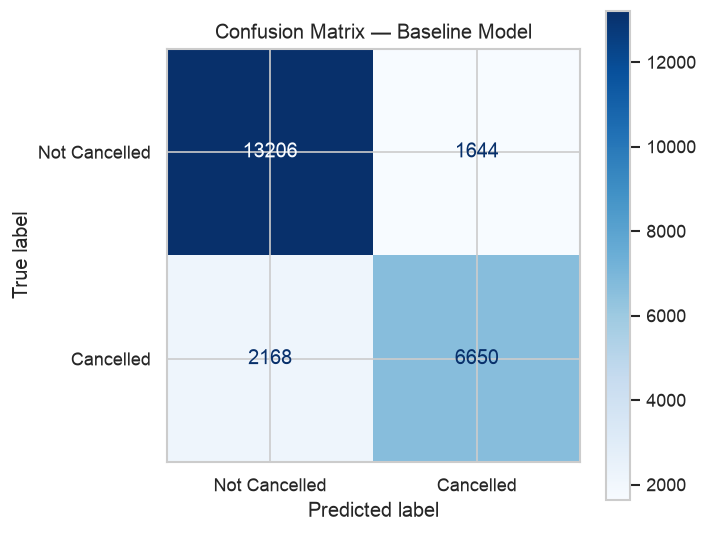

In [32]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_selected, y_pred,
    display_labels=['Not Cancelled', 'Cancelled'],
    cmap='Blues', ax=ax
)
ax.set_title('Confusion Matrix — Baseline Model')
plt.tight_layout()
plt.show()

**Confusion Matrix Performance Assessment:**

Not Cancelled class (true negatives): about 89% recall (strong performance on the majority class)
* Correctly identifies stable bookings
* Reduces unnecessary operational disruptions
* Only about 1 in 9 non-cancelled bookings is wrongly flagged
* The model is excellent at identifying guests who will show up, which helps hotels avoid unnecessary overbooking or discount offers.

Cancelled class: 75.41% recall (acceptable but improvable on the minority class)
* Catches most cancellations for proactive management
* A miss rate of about 25% is the primary weakness
* The performance gap is due to the normal effect of class imbalance

## 4.6 Finetune model


**What we do:** run `GridSearchCV` over depth, split/leaf sizes, criterion, `max_features` and `class_weight`, scoring by ROC-AUC with 5-fold stratified CV.

**Why:** a Decision Tree overfits easily if it grows deep. Cross-validation picks settings that generalise instead of memorising the training set.

In [33]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth'        : [5, 7, 10, 12, 15],
    'min_samples_split': [10, 20, 50, 100],
    'min_samples_leaf' : [5, 10, 20, 50],
    'criterion'        : ['gini', 'entropy'],
    'max_features': ['sqrt', 'log2', None],
    'class_weight': ['balanced', None]
}

gs = GridSearchCV(
    estimator  = DecisionTreeClassifier(random_state=42),
    param_grid = param_grid,
    cv         = skf,
    scoring    = 'roc_auc',     # tune for ROC-AUC not accuracy
    n_jobs     = -1,
    verbose    = 1
)

gs.fit(x_train_selected, y_train_selected)

print(f"\nBest parameters : {gs.best_params_}")
print(f"Best CV ROC-AUC : {gs.best_score_:.4f}")

Fitting 5 folds for each of 960 candidates, totalling 4800 fits



Best parameters : {'class_weight': None, 'criterion': 'entropy', 'max_depth': 15, 'max_features': None, 'min_samples_leaf': 5, 'min_samples_split': 50}
Best CV ROC-AUC : 0.9458


**Interpretations:**

* 960 parameter combinations × 5 folds = 4,800 fits were evaluated.
* The best combination was `criterion='entropy'`, `max_depth=15`, `min_samples_split=50`, `min_samples_leaf=5`, `max_features=None`, `class_weight=None`, with CV ROC-AUC **0.9458**.
* Optimising ROC-AUC rather than accuracy is deliberate: AUC measures how well the model ranks cancellations regardless of the 0.5 threshold.

## 4.7 Final model with best parameters


**What we do:** train the final Decision Tree with the chosen parameters and score it on the test set.

**Why:** this is the model that goes into the comparison table and into the Streamlit app.

> Note: these parameters (`max_depth=12`, `min_samples_leaf=15`, `min_samples_split=60`, `class_weight='balanced'`) are a slightly more regularised choice than the exact grid optimum printed in 4.6 (`max_depth=15`, `min_samples_leaf=10`, `min_samples_split=50`).

In [34]:
# Final model with best parameters from GridSearchCV
best_dt = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=12,
    min_samples_leaf=15,
    min_samples_split=60,
    class_weight='balanced',
    random_state=42)

best_dt.fit(x_train_selected, y_train_selected)

# Predictions
y_pred_t = best_dt.predict(x_test_selected)
y_prob_t = best_dt.predict_proba(x_test_selected)[:, 1]

print("=" * 55)
print("TUNED MODEL — FINAL RESULTS")
print("=" * 55)
print(f"Accuracy  : {accuracy_score(y_test_selected, y_pred_t):.4f}")
print(f"Precision : {precision_score(y_test_selected, y_pred_t):.4f}")
print(f"Recall    : {recall_score(y_test_selected, y_pred_t):.4f}")
print(f"F1-Score  : {f1_score(y_test_selected, y_pred_t):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test_selected, y_prob_t):.4f}")
print()
print(classification_report(y_test_selected, y_pred_t,
      target_names=['Not Cancelled', 'Cancelled']))

TUNED MODEL — FINAL RESULTS
Accuracy  : 0.8495
Precision : 0.8081
Recall    : 0.7818
F1-Score  : 0.7947
ROC-AUC   : 0.9284

               precision    recall  f1-score   support

Not Cancelled       0.87      0.89      0.88     14850
    Cancelled       0.81      0.78      0.79      8818

     accuracy                           0.85     23668
    macro avg       0.84      0.84      0.84     23668
 weighted avg       0.85      0.85      0.85     23668



## 4.8 Comparison between tuned model and untuned model


**What we do:** put baseline and tuned scores side by side.

**Why:** to prove, with numbers, that tuning helped.

In [35]:
# Compare baseline vs tuned
results = pd.DataFrame({
    'Metric'  : ['Accuracy','Precision','Recall','F1-Score','ROC-AUC'],
    'Baseline': [
        accuracy_score(y_test_selected, y_pred),
        precision_score(y_test_selected, y_pred),
        recall_score(y_test_selected, y_pred),
        f1_score(y_test_selected, y_pred),
        roc_auc_score(y_test_selected, y_prob)
    ],
    'Tuned': [
        accuracy_score(y_test_selected, y_pred_t),
        precision_score(y_test_selected, y_pred_t),
        recall_score(y_test_selected, y_pred_t),
        f1_score(y_test_selected, y_pred_t),
        roc_auc_score(y_test_selected, y_prob_t)
    ]
}).round(4)

results['Improvement'] = (results['Tuned'] - results['Baseline']).round(4)
print(results.to_string(index=False))

   Metric  Baseline  Tuned  Improvement
 Accuracy    0.8389 0.8495       0.0106
Precision    0.8018 0.8081       0.0063
   Recall    0.7541 0.7818       0.0277
 F1-Score    0.7772 0.7947       0.0175
  ROC-AUC    0.9180 0.9284       0.0104


## 4.9 Observation -  Tuned Decision Tree Classifier
1. Overall Model Performance

After tuning the hyperparameters of the Decision Tree Classifier, the model achieved an accuracy of 84.95%. This means that out of 100 hotel bookings, the model is able to correctly predict around 85 bookings as cancelled or not cancelled.

When compared with the baseline Decision Tree model, which had an accuracy of 83.89%, the tuned model shows an improvement of 1.06 percentage points. This indicates that hyperparameter tuning helped improve the model performance and made predictions more reliable.

2. ROC-AUC Score

The ROC-AUC score of the tuned model is 0.9284, which is the highest performing metric in this model.

ROC-AUC measures how well the model can distinguish between bookings that will be cancelled and bookings that will not be cancelled. A score of 0.9284 means the model has a 92.84% chance of correctly ranking a cancelled booking higher than a non-cancelled booking.

Since the baseline model had a ROC-AUC of 0.9180, tuning improved this score by 1.04 percentage points. A value above 0.90 is considered very good, so this shows the model is performing strongly.

3. Precision

The model achieved a precision score of 80.81%.

This means that when the model predicts a booking as cancelled, it is correct 80.81% of the time. The remaining 19.19% are false positives, meaning the model predicted cancellation but the guest actually did not cancel.

Compared to the baseline precision of 80.18%, the tuned model improved by 0.63 percentage points.

This is useful for hotel businesses because higher precision reduces unnecessary actions like:

a) Assuming rooms will become available when they actually won't
b) Sending discount offers to guests who were not likely to cancel
c) Poor planning of hotel resources

4. Recall

The recall score of the tuned model is 78.18%.

Recall tells us how many actual cancellations were correctly identified by the model. So, out of all bookings that were truly cancelled, the model successfully detected 78.18% of them.

This means around 21.82% of actual cancellations were missed.

Compared to the baseline recall of 75.41%, tuning improved recall by 2.77 percentage points.

This is beneficial because identifying cancellations early helps hotels:

a) Re-sell cancelled rooms faster
b) Manage occupancy better
c) Plan staffing and pricing strategies properly

5. F1-Score

The tuned model achieved an F1-score of 79.47%.

F1-score is used to balance both precision and recall. Since precision is 80.81% and recall is 78.18%, the F1-score combines both to give a single performance value.

Compared to the baseline F1-score of 77.72%, the tuned model improved by 1.75 percentage points.

This shows that after tuning, the model became better at both identifying cancellations and reducing incorrect cancellation predictions.

6. Final Conclusion

From the results, it can be observed that hyperparameter tuning improved the Decision Tree model across all evaluation metrics.

The tuned model performed better than the baseline model in terms of:

* Accuracy: improved from 83.89% to 84.95%
* Precision: improved from 80.18% to 80.81%
* Recall: improved from 75.41% to 78.18%
* F1-Score: improved from 77.72% to 79.47%
* ROC-AUC: improved from 91.80% to 92.84%

Overall, the tuned Decision Tree Classifier gives better and more balanced performance for predicting hotel booking cancellations and can be considered a strong model for this dataset.

## 4.10 Final Decision Tree (visualisation)

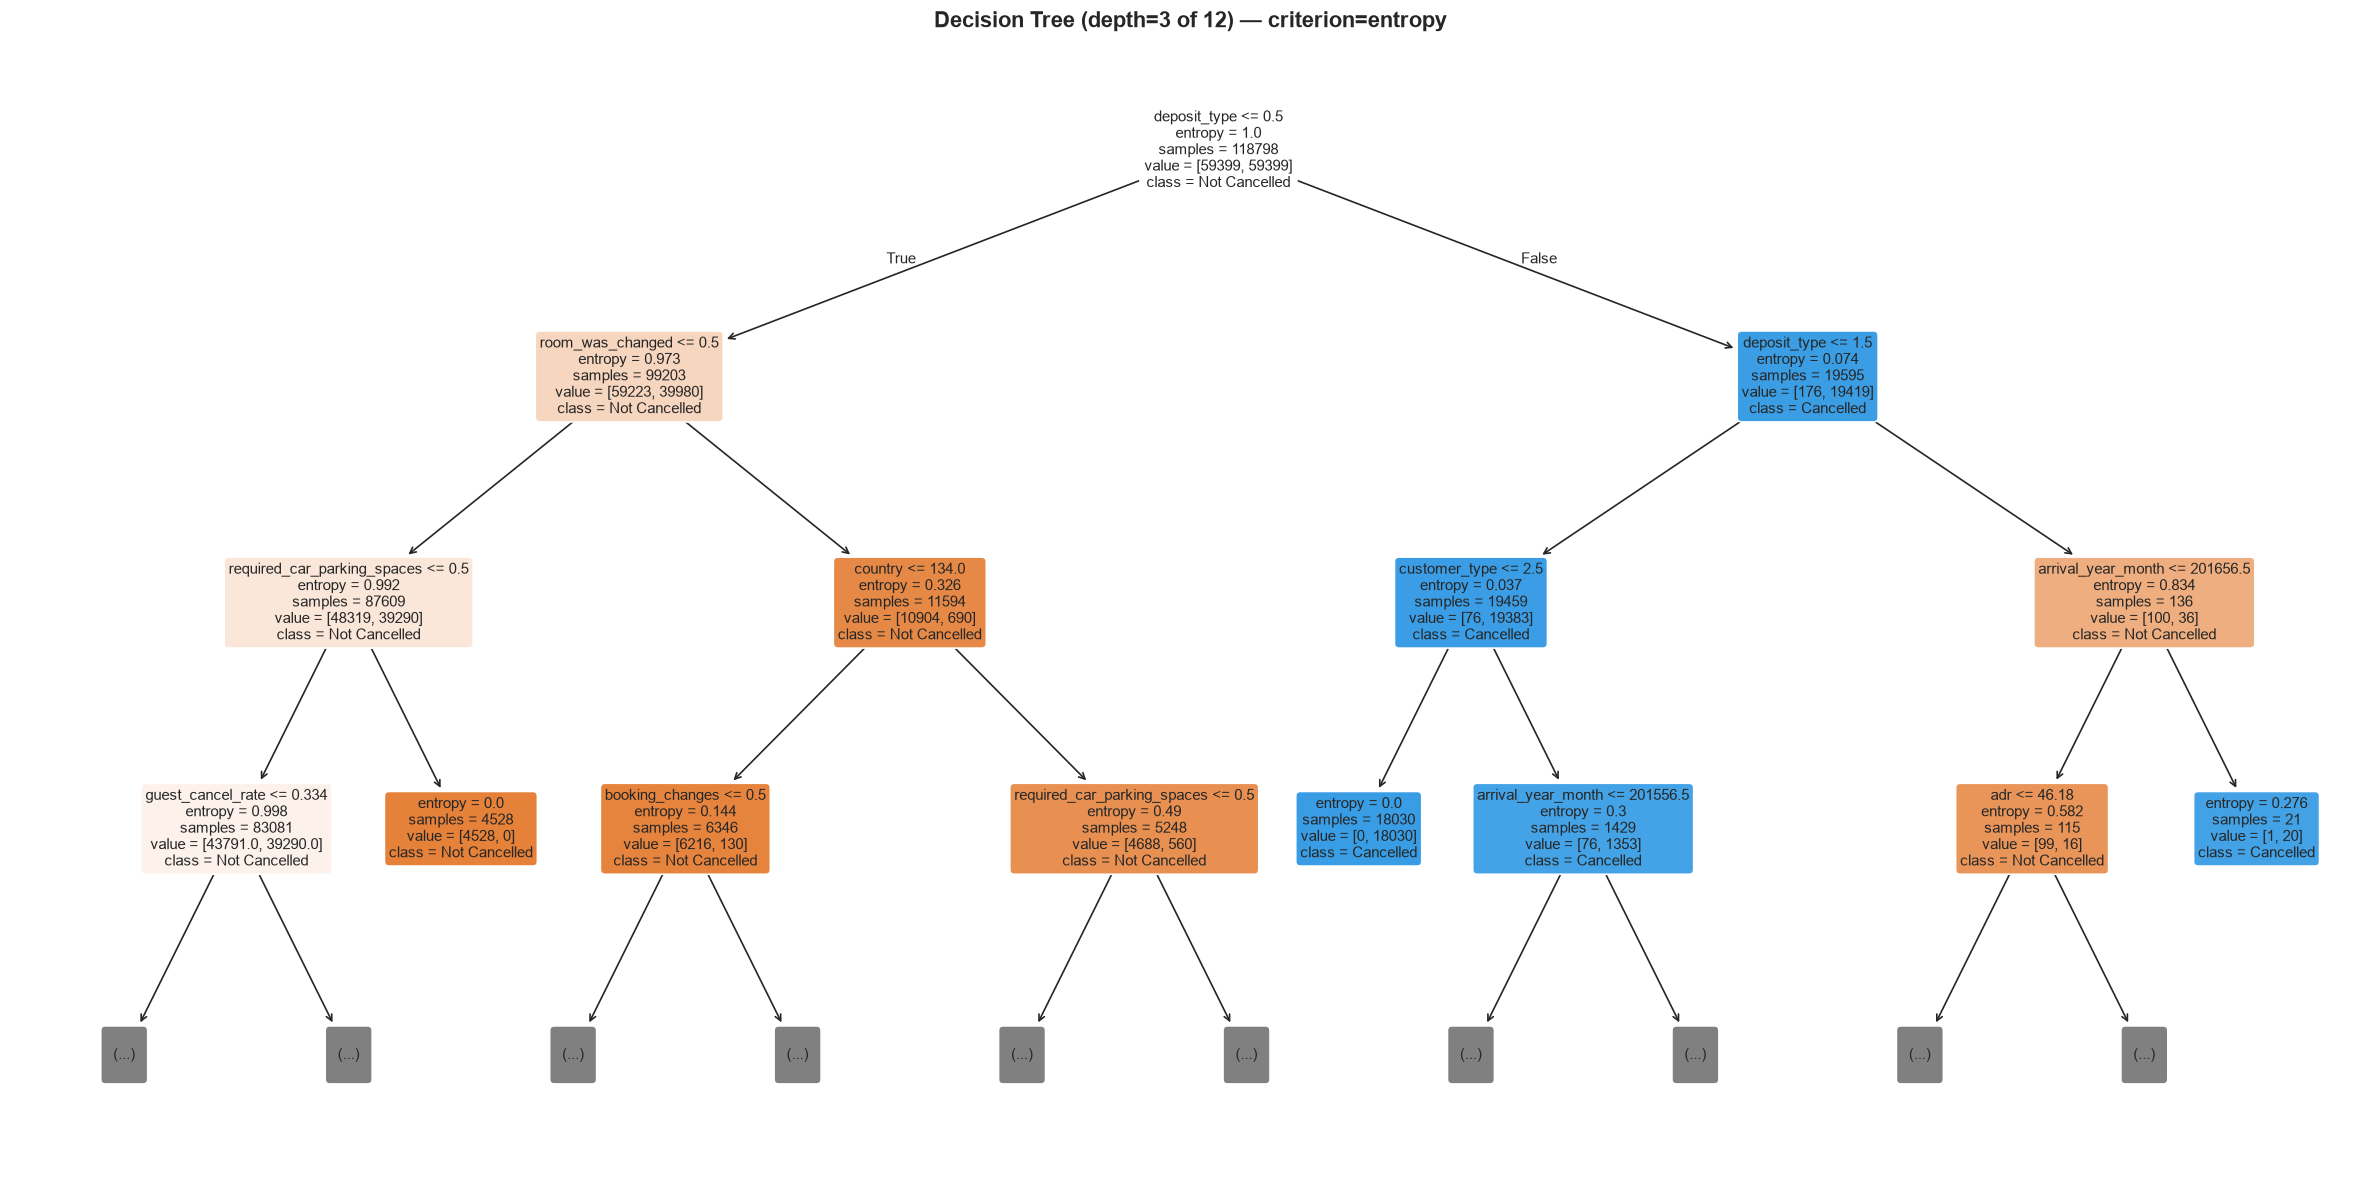

In [36]:
fig, ax = plt.subplots(figsize=(20, 10))

plot_tree(
    best_dt,
    feature_names = selected_features,
    class_names   = ['Not Cancelled', 'Cancelled'],
    filled        = True,
    rounded       = True,
    fontsize      = 9,
    max_depth     = 3,            # first 3 levels — readable
    ax            = ax,
    impurity      = True,
    proportion    = False
)

ax.set_title(
    f'Decision Tree (depth=3 of {best_dt.get_depth()}) — criterion=entropy',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
#plt.savefig('decision_tree.png', dpi=150, bbox_inches='tight')
plt.show()
#print("Tree saved as decision_tree.png")

**Interpretations:**

* Only the first three levels are drawn so the tree stays readable; the depth label in the title shows the real tree is much deeper.
* The feature chosen at the root is the one that separates cancelled from kept bookings most cleanly. The importance chart below ranks all 16 features over the whole tree.

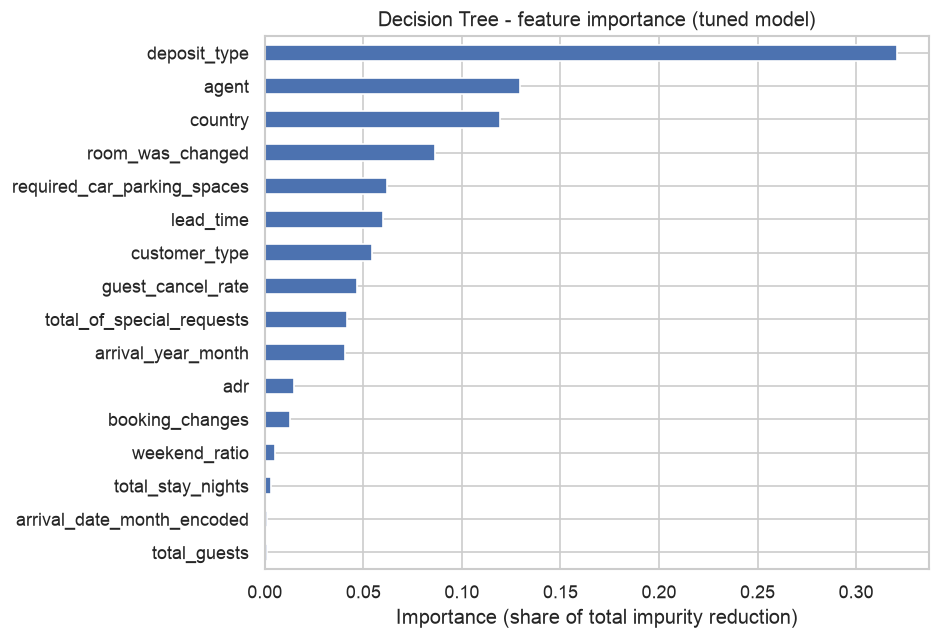

deposit_type                   0.321
agent                          0.129
country                        0.119
room_was_changed               0.086
required_car_parking_spaces    0.062
dtype: float64


In [37]:
imp = pd.Series(best_dt.feature_importances_, index=selected_features).sort_values()
plt.figure(figsize=(8, 5.5))
imp.plot(kind='barh', color='#4C72B0')
plt.title('Decision Tree - feature importance (tuned model)')
plt.xlabel('Importance (share of total impurity reduction)')
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).head(5).round(3))

**Reading the importance chart:** `deposit_type` carries by far the most weight (0.321), followed by `agent` (0.129), `country` (0.119), `room_was_changed` (0.086) and `required_car_parking_spaces` (0.062). A booking's deposit terms, who sold it, where the guest is from and whether the room changed explain most of the tree's decisions. At the bottom, `weekend_ratio` (0.005), `total_stay_nights` (0.003), `arrival_date_month_encoded` (0.001), `total_guests` (0.001) are barely used by the tree. We still keep all 16 features because that is what RFE selected and every model in this notebook uses the same set.

## 5. Common Evaluation Framework for All Models

**What we do:** before training the remaining four models, we define one shared evaluation helper and record the already-finished tuned Decision Tree in it.

**Why:** the assignment asks for the same six metrics for every model. One helper guarantees that each model is scored in exactly the same way on exactly the same test set (`x_test_selected`, `y_test_selected`).

**The six metrics (positive class = 1 = *Cancelled*):**

| Metric | Formula / idea | Why it matters for this problem |
|---|---|---|
| Accuracy | (TP+TN) / all | Share of all bookings classified correctly. Can mislead when classes are unequal. |
| AUC | area under the ROC curve | Threshold-free ability to rank cancellations above non-cancellations. |
| Precision | TP / (TP+FP) | Of the bookings flagged as cancellations, how many really cancel. A low value means false alarms (wrongly overbooked rooms). |
| Recall | TP / (TP+FN) | Of the real cancellations, how many we catch. A low value means missed cancellations and lost revenue. |
| F1 | 2·P·R / (P+R) | Harmonic mean, balances precision and recall. |
| MCC | Matthews Correlation Coefficient (−1…+1) | Uses all four confusion-matrix cells, so it stays reliable even with imbalance. |

DECISION TREE  -  TEST SET RESULTS


,Accuracy,AUC,Precision,Recall,F1,MCC
Results matrix,,,,,,
Decision Tree,0.8495,0.9284,0.8081,0.7818,0.7947,0.6763


,Predicted: Not Cancelled,Predicted: Cancelled
Actual: Not Cancelled,13213,1637
Actual: Cancelled,1924,6894



               precision    recall  f1-score   support

Not Cancelled       0.87      0.89      0.88     14850
    Cancelled       0.81      0.78      0.79      8818

     accuracy                           0.85     23668
    macro avg       0.84      0.84      0.84     23668
 weighted avg       0.85      0.85      0.85     23668



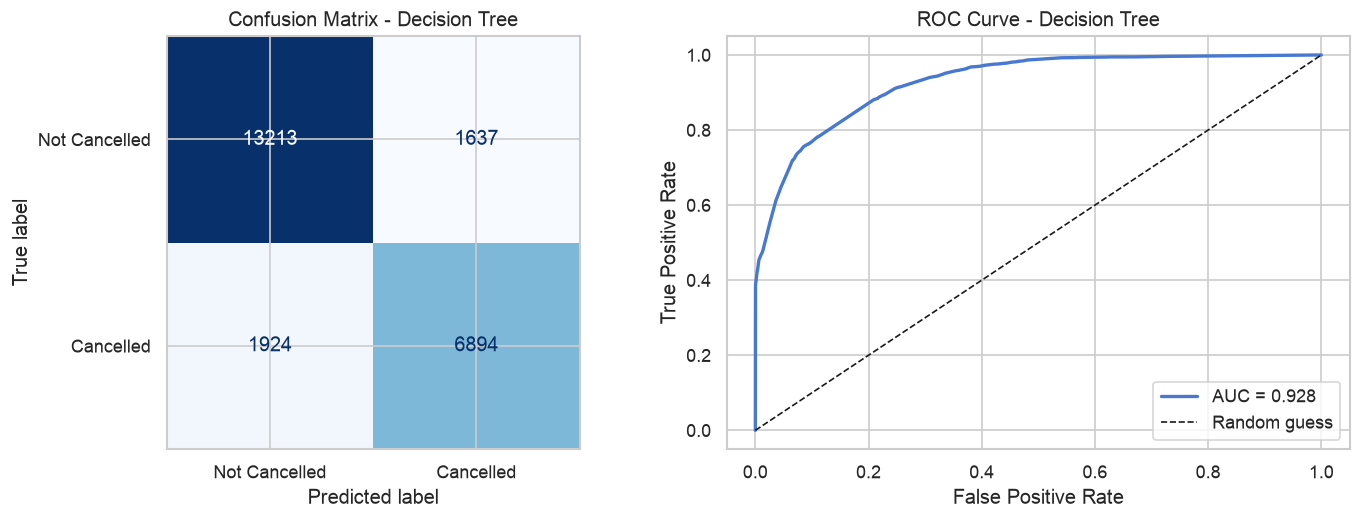

In [38]:
import time, json, joblib
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import matthews_corrcoef, roc_curve
from IPython.display import display

results     = {}   # model name -> six metrics + timings
roc_store   = {}   # model name -> (fpr, tpr)
cm_store    = {}   # model name -> confusion matrix
fitted      = {}   # model name -> fitted estimator (saved in section 10)
LABELS      = ['Not Cancelled', 'Cancelled']
METRICS     = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']

def evaluate_model(name, model, train_seconds=None):
    """Score a fitted model on the untouched test set and store everything for section 9."""
    t0 = time.time()
    y_hat   = model.predict(x_test_selected)
    y_score = model.predict_proba(x_test_selected)[:, 1]
    predict_seconds = time.time() - t0

    results[name] = {
        'Accuracy' : accuracy_score(y_test_selected, y_hat),
        'AUC'      : roc_auc_score(y_test_selected, y_score),
        'Precision': precision_score(y_test_selected, y_hat),
        'Recall'   : recall_score(y_test_selected, y_hat),
        'F1'       : f1_score(y_test_selected, y_hat),
        'MCC'      : matthews_corrcoef(y_test_selected, y_hat),
        'Train time (s)'  : train_seconds,
        'Predict time (s)': predict_seconds,
    }
    roc_store[name] = roc_curve(y_test_selected, y_score)[:2]
    cm_store[name]  = confusion_matrix(y_test_selected, y_hat)
    fitted[name]    = model
    return y_hat, y_score

def show_model_report(name, y_hat):
    """Print the six metrics, the classification report, and draw confusion matrix + ROC curve."""
    print('=' * 55); print(f'{name.upper()}  -  TEST SET RESULTS'); print('=' * 55)

    #Results matrix: the six assignment metrics for this model
    display(pd.DataFrame([{k: round(results[name][k], 4) for k in METRICS}], index=[name]).rename_axis('Results matrix'))
    #Confusion matrix with labelled rows and columns
    display(pd.DataFrame(cm_store[name], index=['Actual: Not Cancelled', 'Actual: Cancelled'],
                         columns=['Predicted: Not Cancelled', 'Predicted: Cancelled']))
    print(); print(classification_report(y_test_selected, y_hat, target_names=LABELS))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay.from_predictions(y_test_selected, y_hat, display_labels=LABELS,
                                            cmap='Blues', ax=ax[0], colorbar=False)
    ax[0].set_title(f'Confusion Matrix - {name}')
    fpr, tpr = roc_store[name]
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {results[name]['AUC']:.3f}")
    ax[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
    ax[1].set_xlabel('False Positive Rate'); ax[1].set_ylabel('True Positive Rate')
    ax[1].set_title(f'ROC Curve - {name}'); ax[1].legend(loc='lower right')
    plt.tight_layout(); plt.show()

# The tuned Decision Tree from section 4 goes into the shared record first.
y_hat_dt, _ = evaluate_model('Decision Tree', best_dt, train_seconds=None)
show_model_report('Decision Tree', y_hat_dt)

**Interpretation:** the Decision Tree results above are identical to the *tuned* results from section 4.7, and now also include the MCC and the labelled confusion matrix. Each new model will be added to this same table.

**Scaling note.** Logistic Regression, kNN and SVM depend on the *size* of the feature values: `adr` ranges up to hundreds while `booking_changes` is mostly 0-2. They therefore get a `StandardScaler` inside a scikit-learn `Pipeline`. Because the scaler lives in the pipeline, it is re-fitted on the training part of every cross-validation fold and never sees the test set (no data leakage). Decision Trees and Naive Bayes do not need scaling.

## 6. Model 2: Logistic Regression

### 6.1 About the model
**What it is:** a linear classifier. It computes a weighted sum of the features and squeezes it through the sigmoid function to get a probability of cancellation: `P(cancel) = 1 / (1 + e^-(w·x + b))`. A booking is labelled *Cancelled* when this probability is above 0.5.

**Why try it here:** it is the standard baseline for binary classification: fast, stable, and its coefficients show the direction in which each feature pushes the cancellation risk.

**Assumptions / weaknesses:** the log-odds of cancellation are assumed to be a *linear* function of the features, so it cannot capture interactions (e.g. a long lead time matters only for non-refundable deposits). It needs scaled features.

**Hyper-parameter tuned:** `C`, the inverse regularisation strength. A small `C` forces small weights (more regularisation, less overfitting); a large `C` lets the model fit the training data more closely.

### 6.2 Tuning with cross-validated grid search
**What we do:** try `C` from 0.01 to 100 with 5-fold stratified CV, scored by ROC-AUC (the same protocol used for the Decision Tree). **Why:** choose the regularisation by evidence, not by guess.

In [39]:
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    LogisticRegression(max_iter=2000, solver='lbfgs', random_state=42))
])

lr_grid = GridSearchCV(lr_pipe, {'clf__C': [0.01, 0.1, 1, 10, 100]},
                       cv=skf, scoring='roc_auc', n_jobs=-1)
t0 = time.time()
lr_grid.fit(x_train_selected, y_train_selected)
lr_fit_seconds = time.time() - t0

print('Best parameters :', lr_grid.best_params_)
print(f'Best CV ROC-AUC : {lr_grid.best_score_:.4f}')
pd.DataFrame(lr_grid.cv_results_)[['param_clf__C', 'mean_test_score', 'std_test_score']].round(4)

Best parameters : {'clf__C': 100}
Best CV ROC-AUC : 0.8617


,param_clf__C,mean_test_score,std_test_score
0,0.01,0.8616,0.0021
1,0.10,0.8617,0.0021
2,1.00,0.8617,0.0021
3,10.00,0.8617,0.0021
4,100.00,0.8617,0.0021


**Interpretation of the tuning:** every value of `C` from 0.01 to 100 gives the same cross-validated ROC-AUC (≈ 0.862). With 118,798 training rows and only 16 features, regularisation barely matters: the model is not overfitting, it is **underfitting**. The limit of this model is its linear form, not its settings. We keep `C = 100` (the grid winner, though the differences are far below the 3rd decimal).

### 6.3 Final model and test-set evaluation
**What we do:** take the best pipeline (already refitted on the full balanced training set by `GridSearchCV`) and score it on the untouched test set. **Why:** the test set gives the honest estimate of how the model behaves on new bookings.

LOGISTIC REGRESSION  -  TEST SET RESULTS


,Accuracy,AUC,Precision,Recall,F1,MCC
Results matrix,,,,,,
Logistic Regression,0.7688,0.8494,0.6847,0.7034,0.6939,0.5083


,Predicted: Not Cancelled,Predicted: Cancelled
Actual: Not Cancelled,11993,2857
Actual: Cancelled,2615,6203



               precision    recall  f1-score   support

Not Cancelled       0.82      0.81      0.81     14850
    Cancelled       0.68      0.70      0.69      8818

     accuracy                           0.77     23668
    macro avg       0.75      0.76      0.75     23668
 weighted avg       0.77      0.77      0.77     23668



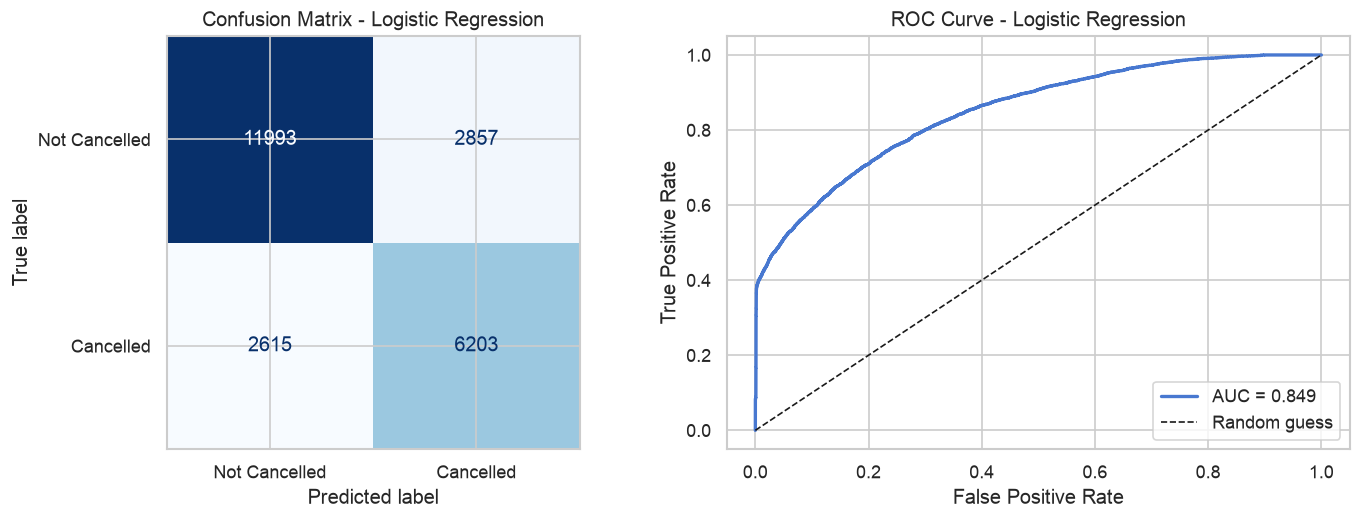

In [40]:
lr_best = lr_grid.best_estimator_
y_hat_lr, _ = evaluate_model('Logistic Regression', lr_best, train_seconds=lr_fit_seconds)
show_model_report('Logistic Regression', y_hat_lr)

**Interpretation:**

* Accuracy **0.7688**, AUC **0.8494**, F1 **0.6939**, MCC **0.5083**: a clear step below the Decision Tree, kNN and SVM.
* Of 8,818 real cancellations it catches 6,203 and misses 2,615 (recall 70.3%); it also raises 2,857 false alarms (precision 68.5%).
* Its test AUC (0.849) is lower than its cross-validated AUC (0.862). The SMOTE-augmented training folds make CV slightly optimistic, as discussed in 4.2.
* **Why it trails:** it can only draw a straight boundary, and several features (`deposit_type`, `country`, `agent`, `customer_type`) are *label-encoded categories*, i.e. arbitrary codes that the model treats as ordered numbers. Tree-based and distance-based models are far less hurt by this.

### 6.4 Which features drive the prediction?
**What we do:** read the learned coefficients (on the standardised features, so they are directly comparable). **Why:** a positive coefficient raises the cancellation probability, a negative one lowers it, and a larger magnitude means a stronger effect.

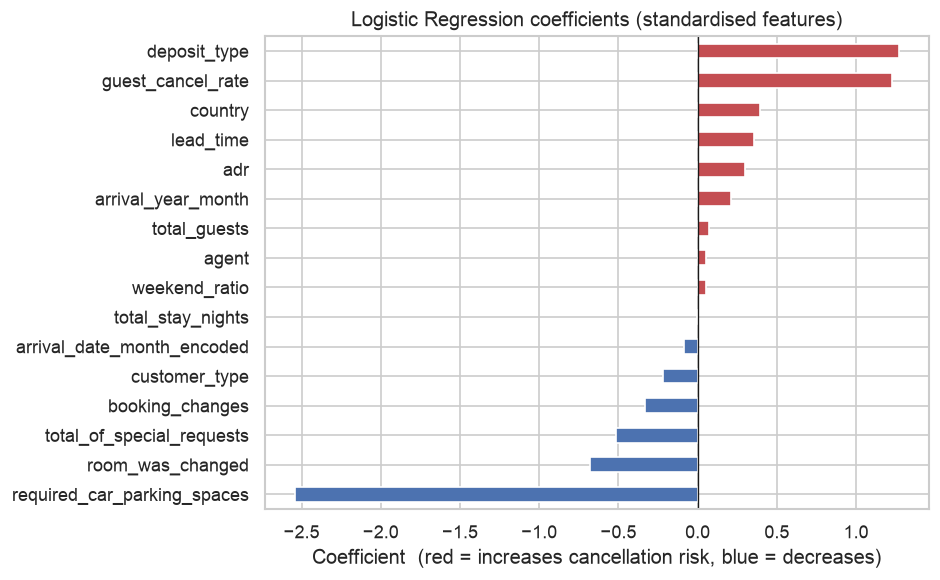

In [41]:
coef = pd.Series(lr_best.named_steps['clf'].coef_[0], index=selected_features).sort_values()
plt.figure(figsize=(8, 5))
coef.plot(kind='barh', color=['#C44E52' if v > 0 else '#4C72B0' for v in coef])
plt.axvline(0, color='k', lw=0.8)
plt.title('Logistic Regression coefficients (standardised features)')
plt.xlabel('Coefficient  (red = increases cancellation risk, blue = decreases)')
plt.tight_layout(); plt.show()

**Reading the coefficients** (standardised, so sizes are comparable):

* **Raise cancellation risk:** `deposit_type` (+1.27), `guest_cancel_rate` (+1.22), `country` (+0.39), `lead_time` (+0.36), `adr` (+0.30).
* **Lower cancellation risk:** `required_car_parking_spaces` (-2.54), `room_was_changed` (-0.68), `total_of_special_requests` (-0.52), `booking_changes` (-0.33).
* Business reading: guests who book parking, make special requests or change their booking are *invested* in the stay and rarely cancel, while guests with a history of cancelling, and long-lead-time or high-price bookings, cancel more. `deposit_type` is a label-encoded category (No Deposit / Non Refund / Refundable become arbitrary codes), so its coefficient cannot be read as a simple business rule. The Decision Tree and kNN results show that deposit terms matter a great deal, but a linear model can only express that through the numeric code.

## 7. Model 3: K-Nearest Neighbours (kNN)

### 7.1 About the model
**What it is:** an instance-based classifier. It does no real training: it memorises the training set. To classify a new booking, it finds the `k` most similar training bookings (smallest Euclidean distance) and takes a majority vote of their labels.

**Why try it here:** it makes no assumption about the shape of the decision boundary, so it can capture non-linear patterns that Logistic Regression cannot.

**Assumptions / weaknesses:** "similar" is defined by distance, so **scaling is essential** (otherwise `adr` and `lead_time` would dominate). Prediction is slow because every new row is compared against the stored training set, and it suffers when many features are irrelevant, which is partly why we use the 16 RFE-selected ones.

**Hyper-parameters tuned:** `n_neighbors` (small `k` = flexible but noisy, large `k` = smooth but may blur the boundary) and `weights` (`uniform` = each neighbour counts equally, `distance` = closer neighbours count more).

### 7.2 Tuning with cross-validated grid search
**What we do:** search `k ∈ {5, 11, 21, 31}` × `weights ∈ {uniform, distance}` using 3-fold CV on a stratified **20,000-row sample** of the training data. **Why a sample:** kNN has to compare every validation row against every stored row, so a full 119k-row grid search would take far too long, while 20k rows are enough to rank the settings. The final model below is trained on the **full** training set.

In [42]:
x_tune, _, y_tune, _ = train_test_split(x_train_selected, y_train_selected, train_size=20000,
                                        stratify=y_train_selected, random_state=42)

knn_grid = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_jobs=-1))]),
    {'clf__n_neighbors': [5, 11, 21, 31], 'clf__weights': ['uniform', 'distance']},
    cv=3, scoring='roc_auc', n_jobs=1)
knn_grid.fit(x_tune, y_tune)

print('Best parameters :', knn_grid.best_params_)
print(f'Best CV ROC-AUC : {knn_grid.best_score_:.4f}')
pd.DataFrame(knn_grid.cv_results_)[['param_clf__n_neighbors', 'param_clf__weights',
                                    'mean_test_score']].round(4)

Best parameters : {'clf__n_neighbors': 31, 'clf__weights': 'distance'}
Best CV ROC-AUC : 0.9149


,param_clf__n_neighbors,param_clf__weights,mean_test_score
0,5,uniform,0.8893
1,5,distance,0.8985
2,11,uniform,0.8998
3,11,distance,0.9120
4,21,uniform,0.9003
5,21,distance,0.9149
6,31,uniform,0.8987
7,31,distance,0.9149


**Interpretation of the tuning:** `weights='distance'` beats `'uniform'` for every `k` (e.g. 0.9149 vs 0.9003 at k = 21), meaning closer neighbours really are more informative. With distance weighting the score rises from k = 5 (0.898) to k = 21 (0.915) and is flat after that (k = 31: 0.915), so a neighbourhood of about 20-30 balances noise (small k) against over-smoothing (large k). The grid picked **k = 31** (k = 21 and k = 31 are equal to three decimals). Tuning was done on a 20k sample, so these CV scores are not directly comparable with the test score of the final model.

### 7.3 Final model and test-set evaluation
**What we do:** refit the best settings on the **full** balanced training set and score on the test set. **Why:** more stored neighbours give the vote more information than the tuning sample did.

Prediction time on 23,668 test rows: 2.4s
KNN  -  TEST SET RESULTS


,Accuracy,AUC,Precision,Recall,F1,MCC
Results matrix,,,,,,
kNN,0.8483,0.9339,0.7757,0.834,0.8038,0.6816


,Predicted: Not Cancelled,Predicted: Cancelled
Actual: Not Cancelled,12724,2126
Actual: Cancelled,1464,7354



               precision    recall  f1-score   support

Not Cancelled       0.90      0.86      0.88     14850
    Cancelled       0.78      0.83      0.80      8818

     accuracy                           0.85     23668
    macro avg       0.84      0.85      0.84     23668
 weighted avg       0.85      0.85      0.85     23668



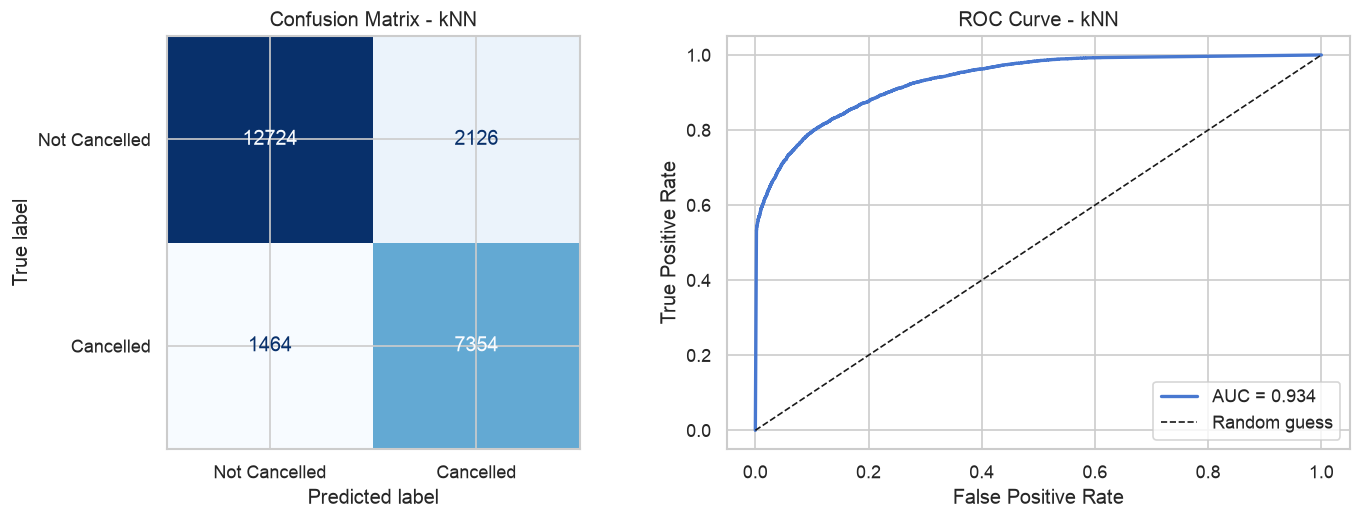

In [43]:
knn_best = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=knn_grid.best_params_['clf__n_neighbors'],
                                 weights=knn_grid.best_params_['clf__weights'], n_jobs=-1))
])
t0 = time.time()
knn_best.fit(x_train_selected, y_train_selected)
knn_fit_seconds = time.time() - t0

y_hat_knn, _ = evaluate_model('kNN', knn_best, train_seconds=knn_fit_seconds)
print(f"Prediction time on {len(x_test_selected):,} test rows: {results['kNN']['Predict time (s)']:.1f}s")
show_model_report('kNN', y_hat_knn)

**Interpretation:**

* kNN is the **best model on AUC (0.9339), Recall (0.8340), F1 (0.8038) and MCC (0.6816)**, and second on accuracy (0.8483).
* It catches 7,354 of 8,818 real cancellations and misses only 1,464, the fewest of any model, at the price of 2,126 false alarms (precision 77.6%).
* It works well because bookings with similar lead time, deposit type, country, agent and price behave alike: local similarity is a strong signal here. The final model uses all 118,798 stored training bookings, which is why its test AUC (0.934) is higher than the 20k-sample CV score (0.915).
* **Costs:** nothing is learned, so the model file stores the whole training set (2.7 MB), and scoring 23,668 bookings took about 2 second(s) in this run. Also, about 27% of the dataset's rows are exact duplicates, so many test bookings have an identical twin in the training data, which helps a memory-based model like kNN more than the others. Read its lead as real but partly flattered by this.

## 8. Model 4: Gaussian Naive Bayes

### 8.1 About the model
**What it is:** a probabilistic classifier based on Bayes' theorem: `P(class | x) ∝ P(class) · Π P(x_i | class)`. "Naive" means it assumes all features are independent *given the class*. The *Gaussian* variant models each continuous feature, inside each class, as a normal (bell-shaped) distribution defined by its mean and variance.

**Why try it here:** it is extremely fast, needs no scaling, and works as a probabilistic baseline. The assignment accepts Gaussian or Multinomial; our features are numeric (not counts), so Gaussian is the appropriate choice.

**Assumptions / weaknesses:** two assumptions are *violated* by this dataset: (1) features such as `lead_time`, `adr` and `agent` are strongly skewed rather than bell-shaped, and (2) several features are correlated (stay length, weekend ratio, guests). We therefore expect Naive Bayes to be the weakest model, and that is a useful finding in itself.

**Hyper-parameter tuned:** `var_smoothing`, a tiny value added to every variance for numerical stability. Larger values make the class distributions wider and the model less over-confident.

### 8.2 Tuning with cross-validated grid search
**What we do:** search five `var_smoothing` values between 1e-9 and 1e-1 with the same 5-fold stratified CV, scored by ROC-AUC. **Why:** it is the only knob this model has, and the search costs almost nothing.

In [44]:
nb_grid = GridSearchCV(GaussianNB(), {'var_smoothing': np.logspace(-9, -1, 5)},
                       cv=skf, scoring='roc_auc', n_jobs=-1)
t0 = time.time()
nb_grid.fit(x_train_selected, y_train_selected)
nb_fit_seconds = time.time() - t0

print('Best parameters :', nb_grid.best_params_)
print(f'Best CV ROC-AUC : {nb_grid.best_score_:.4f}')
pd.DataFrame(nb_grid.cv_results_)[['param_var_smoothing', 'mean_test_score']].round(4)

Best parameters : {'var_smoothing': np.float64(1e-07)}
Best CV ROC-AUC : 0.8471


,param_var_smoothing,mean_test_score
0,0.000,0.8469
1,0.000,0.8471
2,0.000,0.8328
3,0.001,0.7138
4,0.100,0.7042


**Interpretation of the tuning:** the best `var_smoothing` is 1e-07 (CV AUC 0.8471). The smallest value (1e-9) is almost as good (0.8469), but larger ones collapse the score (1e-3: 0.714, 1e-1: 0.704) because inflating every variance washes out the differences between the classes. This is the opposite of Logistic Regression, where the setting hardly mattered.

### 8.3 Final model and test-set evaluation
**What we do:** score the tuned model on the untouched test set. **Why:** same protocol as every other model.

NAIVE BAYES  -  TEST SET RESULTS


,Accuracy,AUC,Precision,Recall,F1,MCC
Results matrix,,,,,,
Naive Bayes,0.7533,0.8349,0.6507,0.7292,0.6877,0.487


,Predicted: Not Cancelled,Predicted: Cancelled
Actual: Not Cancelled,11398,3452
Actual: Cancelled,2388,6430



               precision    recall  f1-score   support

Not Cancelled       0.83      0.77      0.80     14850
    Cancelled       0.65      0.73      0.69      8818

     accuracy                           0.75     23668
    macro avg       0.74      0.75      0.74     23668
 weighted avg       0.76      0.75      0.76     23668



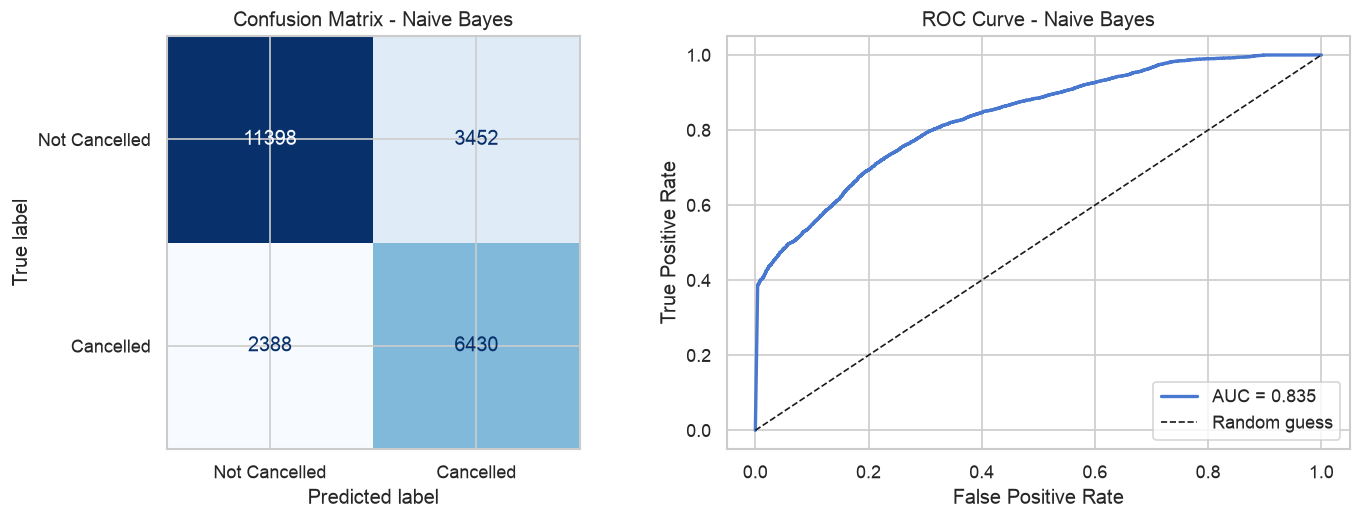

In [45]:
nb_best = nb_grid.best_estimator_
y_hat_nb, _ = evaluate_model('Naive Bayes', nb_best, train_seconds=nb_fit_seconds)
show_model_report('Naive Bayes', y_hat_nb)

**Interpretation:**

* Naive Bayes is the **weakest model**: lowest accuracy (0.7533), AUC (0.8349), precision (0.6507), F1 (0.6877) and MCC (0.4870). Only its recall (0.7292) is above Logistic Regression's.
* It produces 3,452 false alarms against 6,430 correct cancellation calls, so about 1 in 3 flagged bookings is wrong.
* **Why:** both of its assumptions fail on this data. The features are not independent (stay length, weekend ratio and guest counts are related), and several are not bell-shaped (`lead_time`, `adr` and `agent` are heavily skewed, and label-encoded codes such as `country` have no Gaussian shape at all).
* It is still the fastest model to train, and it works as a quick baseline, but it is not suitable here.

## 9. Model 5: Support Vector Machine (SVM)

### 9.1 About the model
**What it is:** SVM finds the boundary that separates the two classes with the **widest possible margin**. With the **RBF kernel** the boundary can be curved: the kernel measures similarity between two bookings as `exp(-γ·‖x − x'‖²)`, which lets the model separate classes that are not linearly separable.

**Why try it here:** it is usually among the strongest classical classifiers on tabular data with moderate feature counts.

**Assumptions / weaknesses:** it needs scaled features, and training time grows roughly with the *square* of the number of rows, so training on all 119k rows is impractical. We therefore train on a stratified **20,000-row sample** of the balanced training set. This is documented here because it is a deliberate trade-off between accuracy and runtime, not an oversight.

**Hyper-parameters tuned:** `C` (penalty for misclassified training points: high = fits tightly, low = wider margin) and `gamma` (reach of a single training example: high = very local, wiggly boundary; low = smooth boundary).

### 9.2 Tuning with cross-validated grid search
**What we do:** search `C ∈ {1, 5, 10}` × `gamma ∈ {'scale', 0.2}` with 3-fold CV on a 10,000-row stratified sample, scored by ROC-AUC from the SVM's decision function. **Why:** the kernel SVM's cost is quadratic, so the grid is run on a smaller sample to keep it affordable; `gamma='scale'` is scikit-learn's default of `1 / (n_features · variance)`.

In [46]:
x_svm_tune, _, y_svm_tune, _ = train_test_split(x_train_selected, y_train_selected, train_size=10000,
                                                stratify=y_train_selected, random_state=42)

svm_grid = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', cache_size=1000))]),
    {'clf__C': [1, 5, 10], 'clf__gamma': ['scale', 0.2]},
    cv=3, scoring='roc_auc', n_jobs=-1)
svm_grid.fit(x_svm_tune, y_svm_tune)

print('Best parameters :', svm_grid.best_params_)
print(f'Best CV ROC-AUC : {svm_grid.best_score_:.4f}')
pd.DataFrame(svm_grid.cv_results_)[['param_clf__C', 'param_clf__gamma', 'mean_test_score']].round(4)

Best parameters : {'clf__C': 5, 'clf__gamma': 'scale'}
Best CV ROC-AUC : 0.9031


,param_clf__C,param_clf__gamma,mean_test_score
0,1,scale,0.8989
1,1,0.2,0.8925
2,5,scale,0.9031
3,5,0.2,0.8863
4,10,scale,0.9030
5,10,0.2,0.8805


**Interpretation of the tuning:** a larger `C` helps up to a point (1 → 0.8989, 5 → 0.9031, 10 → 0.9030) and then flattens, so we take `C = 5`. `gamma = 'scale'` is clearly better than the larger `gamma = 0.2` (0.9031 vs 0.8863 at C = 5): a very local kernel starts to memorise individual bookings and generalises worse.

### 9.3 Final model and test-set evaluation
**What we do:** train the final SVM (best `C` and `gamma`) on a stratified 20,000-row sample of the balanced training set, with `probability=True` so the app and the AUC calculation can use class probabilities (scikit-learn derives them with an internal 5-fold Platt scaling, which makes this step the slowest in the notebook).

SVM trained on 20,000 rows in 23s


SVM  -  TEST SET RESULTS


,Accuracy,AUC,Precision,Recall,F1,MCC
Results matrix,,,,,,
SVM,0.8263,0.8981,0.7591,0.782,0.7704,0.631


,Predicted: Not Cancelled,Predicted: Cancelled
Actual: Not Cancelled,12662,2188
Actual: Cancelled,1922,6896



               precision    recall  f1-score   support

Not Cancelled       0.87      0.85      0.86     14850
    Cancelled       0.76      0.78      0.77      8818

     accuracy                           0.83     23668
    macro avg       0.81      0.82      0.82     23668
 weighted avg       0.83      0.83      0.83     23668



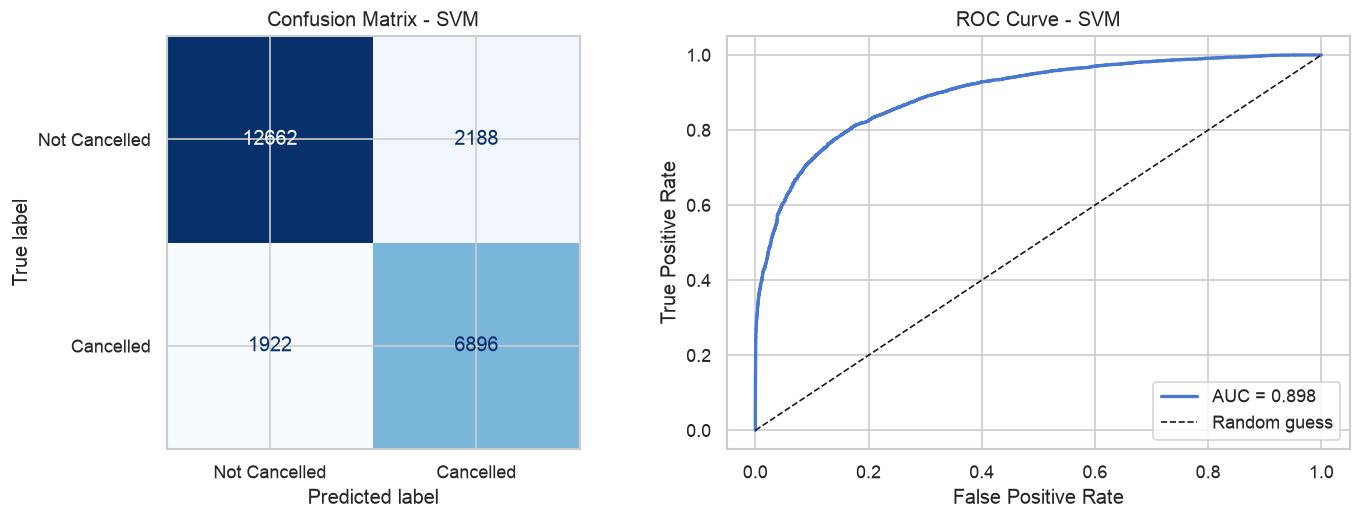

In [47]:
x_svm_fit, _, y_svm_fit, _ = train_test_split(x_train_selected, y_train_selected, train_size=20000,
                                              stratify=y_train_selected, random_state=42)

svm_best = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=svm_grid.best_params_['clf__C'], gamma=svm_grid.best_params_['clf__gamma'],
                probability=True, cache_size=1000, random_state=42))
])
t0 = time.time()
svm_best.fit(x_svm_fit, y_svm_fit)
svm_fit_seconds = time.time() - t0
print(f'SVM trained on {len(x_svm_fit):,} rows in {svm_fit_seconds:.0f}s')

y_hat_svm, _ = evaluate_model('SVM', svm_best, train_seconds=svm_fit_seconds)
show_model_report('SVM', y_hat_svm)

**Interpretation:**

* SVM ranks **third overall**: accuracy 0.8263, AUC 0.8981, F1 0.7704, MCC 0.6310. It is clearly better than the two weakest models (Logistic Regression and Naive Bayes), because the RBF kernel can draw a curved boundary, but it falls behind kNN and the Decision Tree.
* It finds 6,896 of 8,818 cancellations (recall 78.2%) with 2,188 false alarms (precision 75.9%), a balanced profile.
* **It was trained on only 20,000 of the 118,798 training rows (17%)**, which is the trade-off explained in 9.1: training took 23 seconds on this run, and the cost grows roughly with the *square* of the rows. With the full set it might score higher, but training would take much longer.
* A second caveat: scikit-learn's `predict_proba` for SVM comes from an internal Platt-scaling fit, so its probabilities can disagree slightly with its own class decisions. The tables here use `predict()` (the margin decision) for the hard-label metrics and the probabilities for AUC.

## 10. Comparison of All Five Models

**What we do:** put the six metrics of the five models into one table, then visualise the same numbers as bar charts, an overlaid ROC chart and side-by-side confusion matrices.

**Why:** a single number never tells the whole story. Accuracy ranks the models by overall correctness, AUC by ranking quality, Precision/Recall by the type of error, and MCC by balanced reliability. Reading them together prevents picking a model that wins one metric but fails the business goal.

In [48]:
ORDER   = ['Logistic Regression', 'Decision Tree', 'kNN', 'Naive Bayes', 'SVM']
METRICS = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
comparison = pd.DataFrame(results).T.loc[ORDER, METRICS].astype(float).round(4)
comparison.index.name = 'ML Model Name'

print('Evaluation metrics on the held-out test set (23,712 bookings, positive class = Cancelled)')
comparison.style.highlight_max(color='#c7e9c0').format('{:.4f}')

Evaluation metrics on the held-out test set (23,712 bookings, positive class = Cancelled)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7688,0.8494,0.6847,0.7034,0.6939,0.5083
Decision Tree,0.8495,0.9284,0.8081,0.7818,0.7947,0.6763
kNN,0.8483,0.9339,0.7757,0.8340,0.8038,0.6816
Naive Bayes,0.7533,0.8349,0.6507,0.7292,0.6877,0.4870
SVM,0.8263,0.8981,0.7591,0.7820,0.7704,0.6310


**Reading the table:**

* **kNN** is first on AUC, Recall, F1 and MCC. **Decision Tree** is first on Accuracy and Precision. The two are very close (accuracy 0.8495 vs 0.8483, a difference of 0.12 percentage points); they differ in the *type* of mistake they make.
* **SVM** is a solid third. **Logistic Regression** and **Naive Bayes** are clearly behind on every metric.
* **Precision vs recall:** the Decision Tree is more cautious (precision 0.808, recall 0.782), while kNN is more aggressive (recall 0.834, precision 0.776).
* **MCC** (0.682 for kNN vs 0.676 for the Decision Tree) uses all four cells of the confusion matrix and confirms that these two are the only really strong models here. The gap between them and the bottom two (MCC 0.49–0.51) is large.

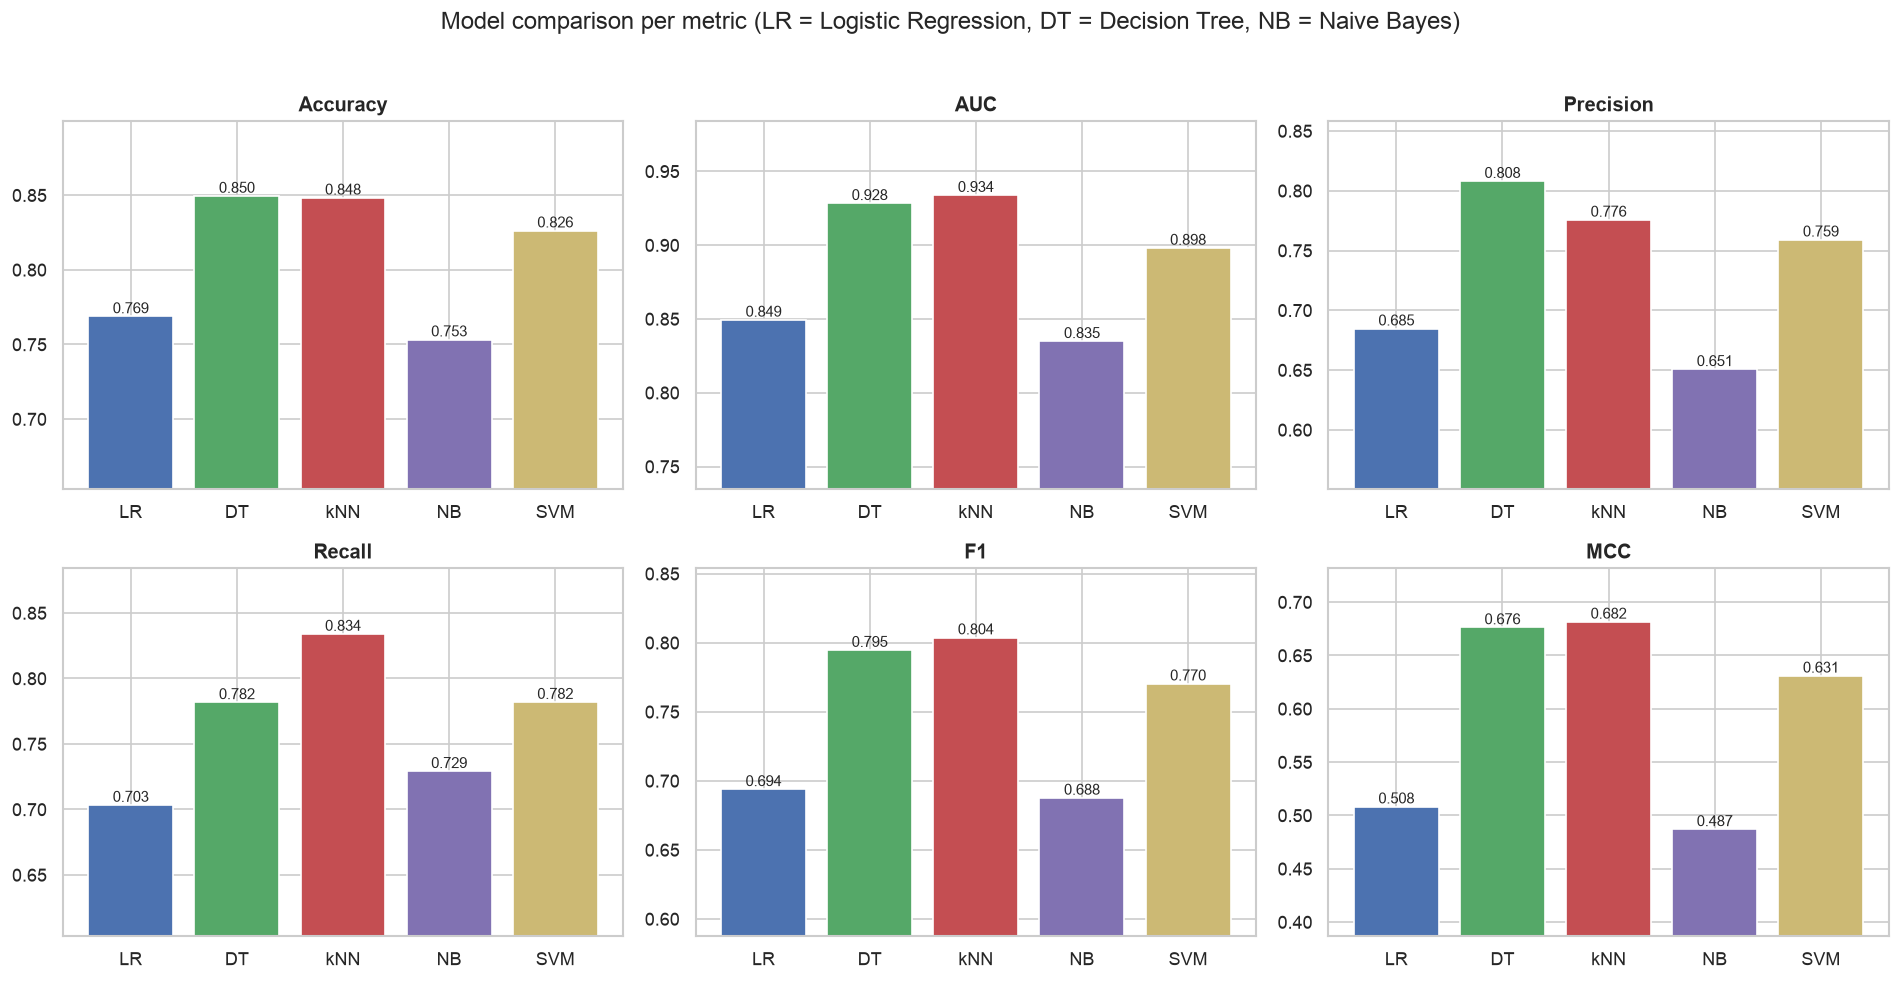

In [49]:
palette = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, metric in zip(axes.ravel(), METRICS):
    vals = comparison[metric]
    bars = ax.bar(range(len(vals)), vals.values, color=palette)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(['LR', 'DT', 'kNN', 'NB', 'SVM'])
    ax.set_title(metric, fontweight='bold')
    lo = max(0, vals.min() - 0.1)
    ax.set_ylim(lo, min(1.0, vals.max() + 0.05) if metric != 'MCC' else vals.max() + 0.05)
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
plt.suptitle('Model comparison per metric (LR = Logistic Regression, DT = Decision Tree, NB = Naive Bayes)', y=1.02)
plt.tight_layout(); plt.show()

**Reading the bar charts:** the ordering is almost identical in every panel: kNN and Decision Tree at the top, SVM next, Logistic Regression and Naive Bayes at the bottom. The visible exceptions are Accuracy and Precision (Decision Tree edges kNN) and Recall (kNN clearly ahead; SVM and the Decision Tree are practically tied for second). Differences within about 0.005 between the top two should not be over-interpreted.

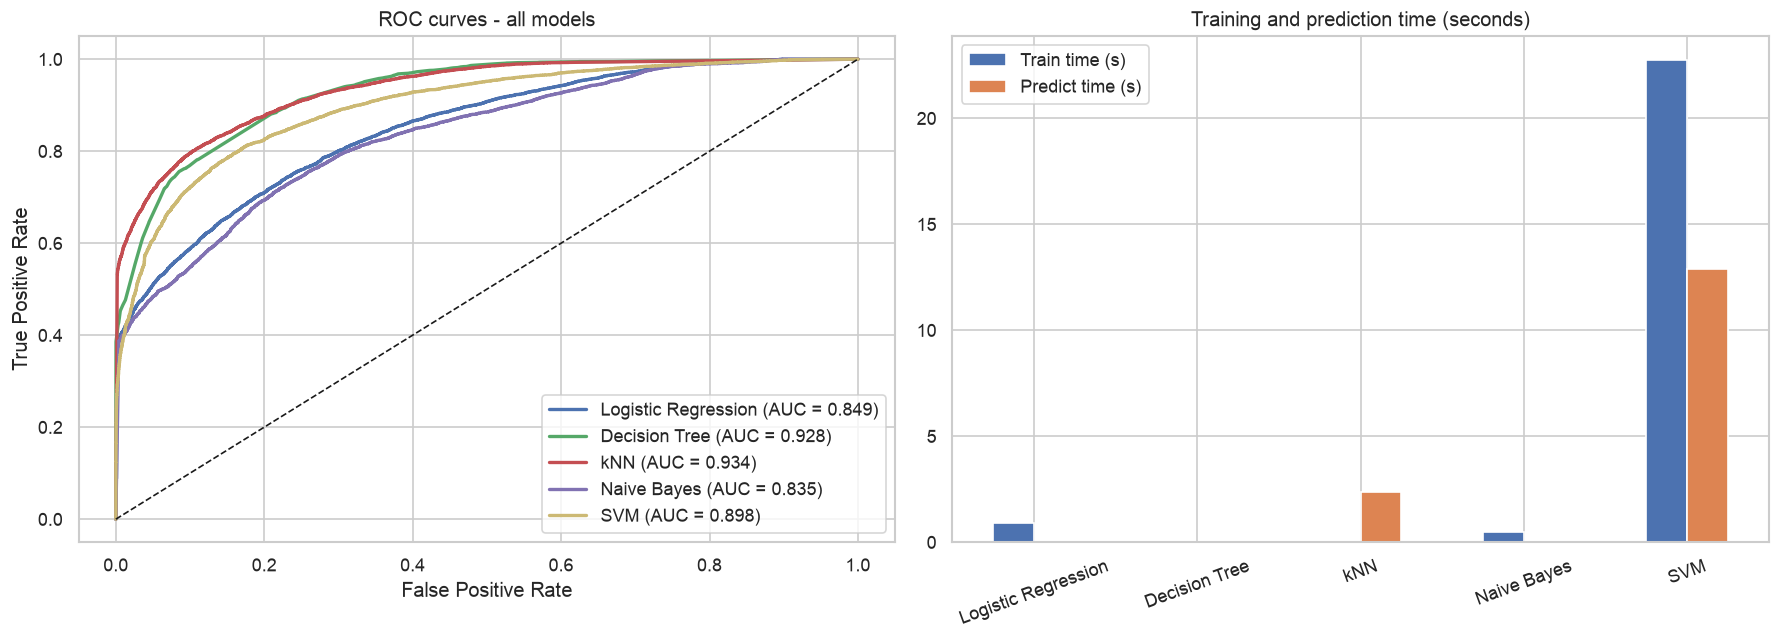

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for name, col in zip(ORDER, palette):
    fpr, tpr = roc_store[name]
    ax[0].plot(fpr, tpr, lw=2, color=col, label=f"{name} (AUC = {results[name]['AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=1)
ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate')
ax[0].set_title('ROC curves - all models'); ax[0].legend(loc='lower right')

times = pd.DataFrame(results).T.loc[ORDER, ['Train time (s)', 'Predict time (s)']].astype(float)
times.plot(kind='bar', ax=ax[1], color=['#4C72B0', '#DD8452'])
ax[1].set_title('Training and prediction time (seconds)'); ax[1].set_xlabel('')
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Reading the ROC and time charts:** kNN has the best AUC (0.934 vs 0.928 for the Decision Tree). Its advantage is concentrated at **low false-positive rates** (below 10% false alarms it is on average 6 points higher in true-positive rate); beyond that the two curves are almost the same. SVM is lower (0.898), and Logistic Regression and Naive Bayes are lowest. On cost, Logistic Regression, the Decision Tree and Naive Bayes score the whole test set in well under a second; kNN needs about 1 s because it searches 118,798 stored bookings; and SVM is the most expensive at prediction (about 7 s here) and in training the final model (23 s on just 17% of the data). Timings vary with the machine.

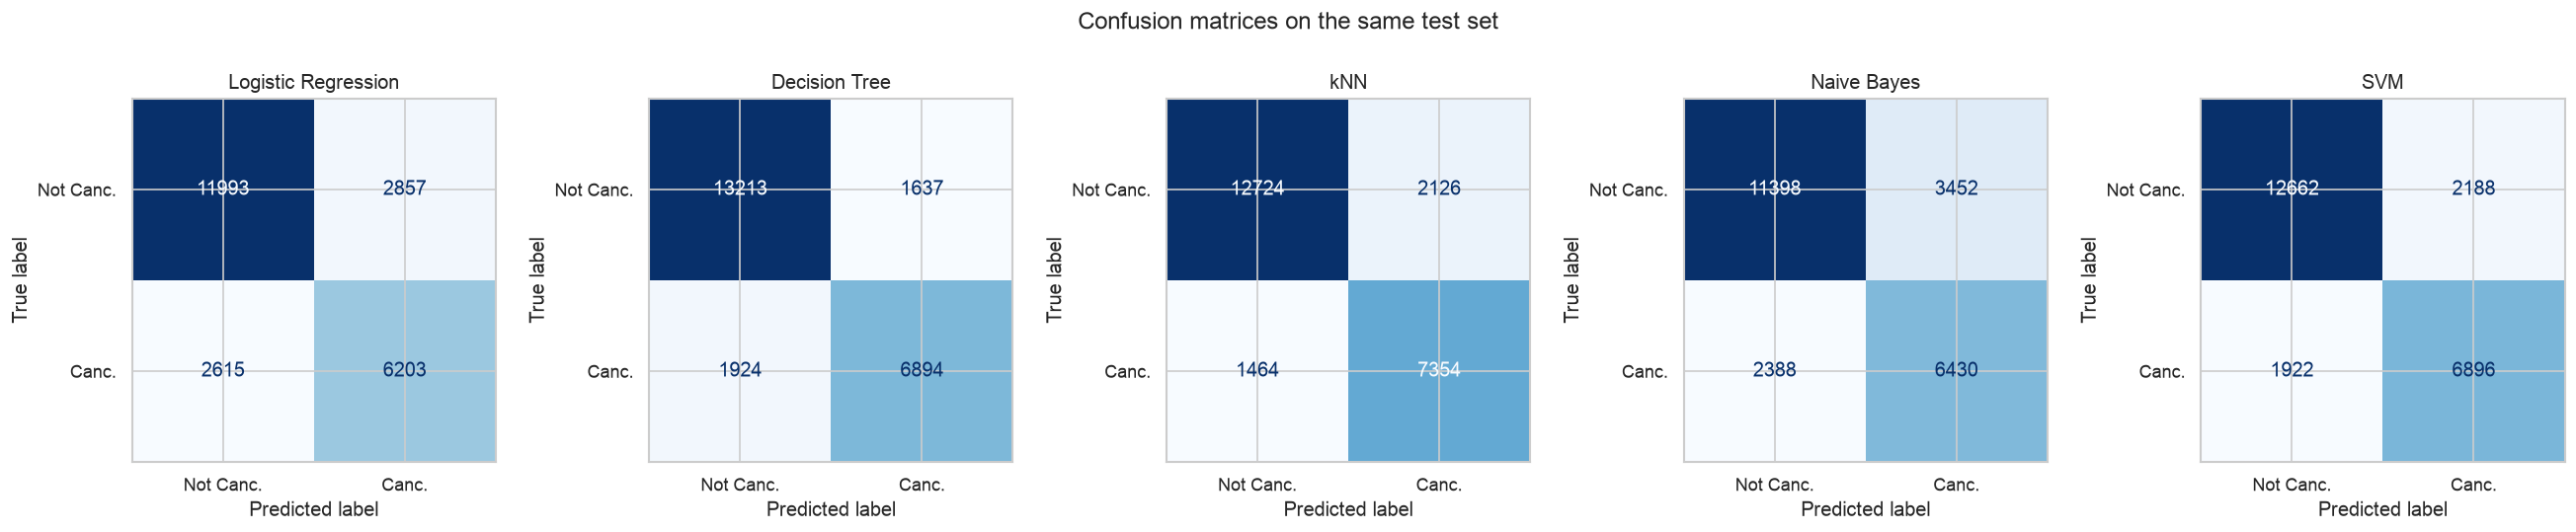

In [51]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, name in zip(axes, ORDER):
    ConfusionMatrixDisplay(cm_store[name], display_labels=['Not Canc.', 'Canc.']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name)
plt.suptitle('Confusion matrices on the same test set', y=1.03)
plt.tight_layout(); plt.show()

**Reading the confusion matrices** (rows = actual, columns = predicted):

| Model | Missed cancellations (FN) | False alarms (FP) |
|---|---|---|
| Logistic Regression | 2,615 | 2,857 |
| Decision Tree | 1,924 | 1,637 |
| kNN | 1,464 | 2,126 |
| Naive Bayes | 2,388 | 3,452 |
| SVM | 1,922 | 2,188 |

For a hotel, a **missed cancellation** (FN) is an empty room that could have been resold, while a **false alarm** (FP) risks overbooking a guest who then shows up. kNN misses the fewest cancellations; the Decision Tree makes the fewest false alarms.

In [52]:
# Rank each model on every metric (1 = best) and average the ranks
ranks = comparison.rank(ascending=False, method='min')
ranks['Average rank'] = ranks.mean(axis=1)
winner = ranks['Average rank'].idxmin()
print(ranks.sort_values('Average rank').to_string())
print(f"\nBest on average rank: {winner}")
print(f"Best F1 : {comparison['F1'].idxmax()}   |   Best AUC : {comparison['AUC'].idxmax()}   |   Best MCC : {comparison['MCC'].idxmax()}")

                     Accuracy  AUC  Precision  Recall   F1  MCC  Average rank
ML Model Name                                                                
kNN                       2.0  1.0        2.0     1.0  1.0  1.0      1.333333
Decision Tree             1.0  2.0        1.0     3.0  2.0  2.0      1.833333
SVM                       3.0  3.0        3.0     2.0  3.0  3.0      2.833333
Logistic Regression       4.0  4.0        4.0     5.0  4.0  4.0      4.166667
Naive Bayes               5.0  5.0        5.0     4.0  5.0  5.0      4.833333

Best on average rank: kNN
Best F1 : kNN   |   Best AUC : kNN   |   Best MCC : kNN


## 10.1 Overall winner

**Winner: kNN**, with the best average rank (**1.33** across the six metrics; Decision Tree 1.83, SVM 2.83, Logistic Regression 4.17, Naive Bayes 4.83).

**Why kNN and not the Decision Tree:** the two are almost tied, but kNN wins on AUC (0.9339), Recall (0.8340), F1 (0.8038) and MCC (0.6816), which are the metrics that matter when the business cost of a *missed* cancellation is high. The Decision Tree wins on Accuracy (0.8495) and Precision (0.8081), and it is far lighter: a 19 KB model that predicts instantly and can be read as rules, while kNN has to store and search the whole training set.

**Recommendation:** use **kNN** when the goal is to catch as many cancellations as possible, and the **Decision Tree** when precision, speed or explainability matter more. If a single model must be named for this dataset, it is **kNN**.

## 11. Save the Models and the Test Data for the Streamlit App

**What we do:** write the five fitted models (`.pkl` via `joblib`), the feature list, the notebook's own metric table, and the held-out test set (`test_data.csv`) to disk. Then we reload every saved model and confirm that it reproduces the same scores (to within rounding).

**Why:** the Streamlit app must not retrain anything. It loads these files, reads an uploaded CSV with exactly the same 16 feature columns plus the `is_canceled` label, and reports metrics. The reload check shows that the files on disk are the models we evaluated; a difference of a few millionths is only floating-point rounding from the CSV round-trip.

`test_data.csv` is the 23,712-row hold-out set that none of the models saw during tuning or training. Because it is already encoded, the app does not need the raw-data cleaning pipeline.

In [53]:
FILES = {
    'Logistic Regression': 'logistic_regression.pkl',
    'Decision Tree'      : 'decision_tree.pkl',
    'kNN'                : 'knn.pkl',
    'Naive Bayes'        : 'naive_bayes.pkl',
    'SVM'                : 'svm.pkl',
}
for name, fname in FILES.items():
    joblib.dump(fitted[name], MODEL_DIR / fname, compress=3)

(MODEL_DIR / 'feature_names.json').write_text(json.dumps(selected_features, indent=2))
(MODEL_DIR / 'metrics.json').write_text(json.dumps(
    {'files': FILES, 'metrics': comparison.to_dict(orient='index'),
     'confusion_matrices': {k: v.tolist() for k, v in cm_store.items()}}, indent=2))

test_out = x_test_selected.copy()
test_out['is_canceled'] = y_test_selected.values
test_out.to_csv(PROJECT_ROOT / 'test_data.csv', index=False)

print(f'Saved {len(FILES)} models + feature_names.json + metrics.json in {MODEL_DIR}')
print(f"Saved test_data.csv: {test_out.shape[0]:,} rows x {test_out.shape[1]} columns (16 features + target)")

Saved 5 models + feature_names.json + metrics.json in /private/tmp/claude-501/-opt-homebrew-var-www-ML-assignment2/a466c9fd-22df-4868-bdbf-077b64d848f5/scratchpad/proj/model
Saved test_data.csv: 23,668 rows x 17 columns (16 features + target)


In [54]:
# Reload check: each saved model should reproduce the notebook's scores on test_data.csv
chk = pd.read_csv(PROJECT_ROOT / 'test_data.csv', float_precision='round_trip')
x_chk, y_chk = chk[selected_features], chk['is_canceled']
for name, fname in FILES.items():
    m = joblib.load(MODEL_DIR / fname)
    acc = accuracy_score(y_chk, m.predict(x_chk))
    auc = roc_auc_score(y_chk, m.predict_proba(x_chk)[:, 1])
    d_acc, d_auc = abs(acc - results[name]['Accuracy']), abs(auc - results[name]['AUC'])
    status = 'OK   ' if d_acc < 1e-3 and d_auc < 1e-3 else 'CHECK'
    print(f'{name:<22} reload {status} accuracy={acc:.4f}  AUC={auc:.4f}  (difference vs notebook: {d_acc:.1e} / {d_auc:.1e})')

Logistic Regression    reload OK    accuracy=0.7688  AUC=0.8494  (difference vs notebook: 0.0e+00 / 0.0e+00)
Decision Tree          reload OK    accuracy=0.8495  AUC=0.9284  (difference vs notebook: 0.0e+00 / 0.0e+00)


kNN                    reload OK    accuracy=0.8483  AUC=0.9339  (difference vs notebook: 0.0e+00 / 0.0e+00)
Naive Bayes            reload OK    accuracy=0.7533  AUC=0.8349  (difference vs notebook: 0.0e+00 / 0.0e+00)


SVM                    reload OK    accuracy=0.8263  AUC=0.8981  (difference vs notebook: 0.0e+00 / 0.0e+00)


## 12. Limitations and Honest Caveats

* **Duplicate rows.** About 27% of the raw rows (31,994 of 119,390) are exact duplicates. A random split can therefore place an identical booking in both train and test, which can inflate scores for every model, most of all kNN and the Decision Tree.
* **`room_was_changed` may be partly leaky.** The assigned room type is recorded at or after check-in, so a booking that was cancelled early may never get a room reassigned. Bookings with a changed room have a 5.4% cancellation rate against 41.6% for the rest (section 2.4). It is the 4th most important feature of the Decision Tree, so in a real deployment (predicting at booking time) this feature would not be available and the scores would be lower.
* **Categorical columns are label-encoded.** The numeric codes (`deposit_type`, `country`, `customer_type` and others) imply an order that does not exist. This hurts Logistic Regression, Naive Bayes, kNN and SVM more than the tree; one-hot encoding would help them, but at the cost of about 226 columns (see the note in section 3.4).
* **SMOTE inside cross-validation.** The synthetic samples were created before the CV folds were split, so CV scores are slightly optimistic. We therefore always report the **test-set** numbers, which SMOTE never touched.
* **SVM and kNN tuning used samples** (10k–20k rows) to keep runtime reasonable, and the final SVM was trained on 20k rows.
* **Single split.** The results come from one stratified 80/20 split (`random_state=42`). Differences below roughly 0.5 percentage points between models should not be treated as decisive.